# Field reconstruction and calibration
This notebook separates three questions: which tracker reconstructs the field better, whether posterior averaging improves on the identical modal estimate, and what useful uncertainty information the distribution provides.

The application uses eight orthonormal DCT spatial modes on an 8-by-8 grid, rank-three changing subspaces, and supplied motion equal to half the physical motion. Passive data and known calibration patterns are separate protocols. Validation trajectories choose benchmark settings independently of evaluation data. Mean and mode share the same Bingham parameters; the mode equals matching EW PCA.

Figures use larger canvases, TeX, and 200 dpi. Signed gain maps, paired trials, spatial errors, coverage forests, and cost–accuracy plots replace repeated trajectory curves. The application has only eight independent repetitions per scenario; intervals should be read as exploratory pilot evidence.

In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess
ROOT=Path.cwd() if (Path.cwd()/'lib').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from lib.validation import require_gate
print('Numerical core:',require_gate(ROOT)['status'])
from lib.plotting import plt
from lib.reporting import run_or_load
from lib.visuals import (array_overview,field_overview,paired_field,coverage_regions,
    cost_tradeoff,field_maps,calibration_overview,noise_overview,sampler_overview,predictive_scores)
from lib.decision_visuals import load_study,gain_maps,decision_calibration
import numpy as np
import pandas as pd
from IPython.display import display
OUT=ROOT/'results'
assert plt.rcParams['text.usetex'] and plt.rcParams['figure.dpi']==200
assert plt.rcParams['savefig.dpi']==200

def show(fig):
    assert fig.dpi==200
    plt.show()
    plt.close(fig)

# Unchanged raw application simulations are checksum-verified and reused.
config=dict(repeats=8,T=72,draws=6000,burnin=2500,max_draws=24000,max_burnin=8000)

result=run_or_load(ROOT,'case2',dict(seed=2718,**config))
m=result['metrics'];c=result['calibration'];noise=result['noise']
display(result['config'])

Numerical core: passed


case2: loading verified simulation tables


{'seed': 2718,
 'repeats': 8,
 'T': 72,
 'draws': 6000,
 'burnin': 2500,
 'n': 8,
 'k': 3,
 'd': 64,
 's': 0.2,
 'tau2': 1.5,
 'checkpoints': [12, 36, 72],
 'max_draws': 24000,
 'max_burnin': 8000,
 'known_motion_fraction': 0.5,
 'nominal_mass': 0.95,
 'validation_candidates': 3,
 'spatial_basis': 'Eight low-frequency separable DCT-II modes on an 8x8 grid',
 'calibration_input_rank': 'Rank of supplied-frame transported preassigned inputs',
 'coverage_distribution': 'Independent Gaussian-QR initial subspaces, Gaussian skew drift paths, and Gaussian observations',
 'coverage_guaranteed': False,
 'noise_fit_ascent_verified': False,
 'score_method': 'Prior Monte Carlo log-mean-exp, with importance ESS and chain discrepancy'}

## Attribute the gains correctly
The three maps compare the posterior mean against GROUSE, its **own mode**, and rolling PCA. Blue means lower field MSE; red means higher MSE. Cells show paired absolute-loss differences scaled by the observed mean reference loss, with paired 95% intervals on that scale—not a confidence interval for a random loss ratio.

Large gains versus GROUSE under mismatch should not be attributed entirely to Bayesian averaging: the mode/EW-PCA control already captures most of them. The rolling-PCA panel prevents selecting only a weak reference. Intervals crossing zero do not establish a difference.

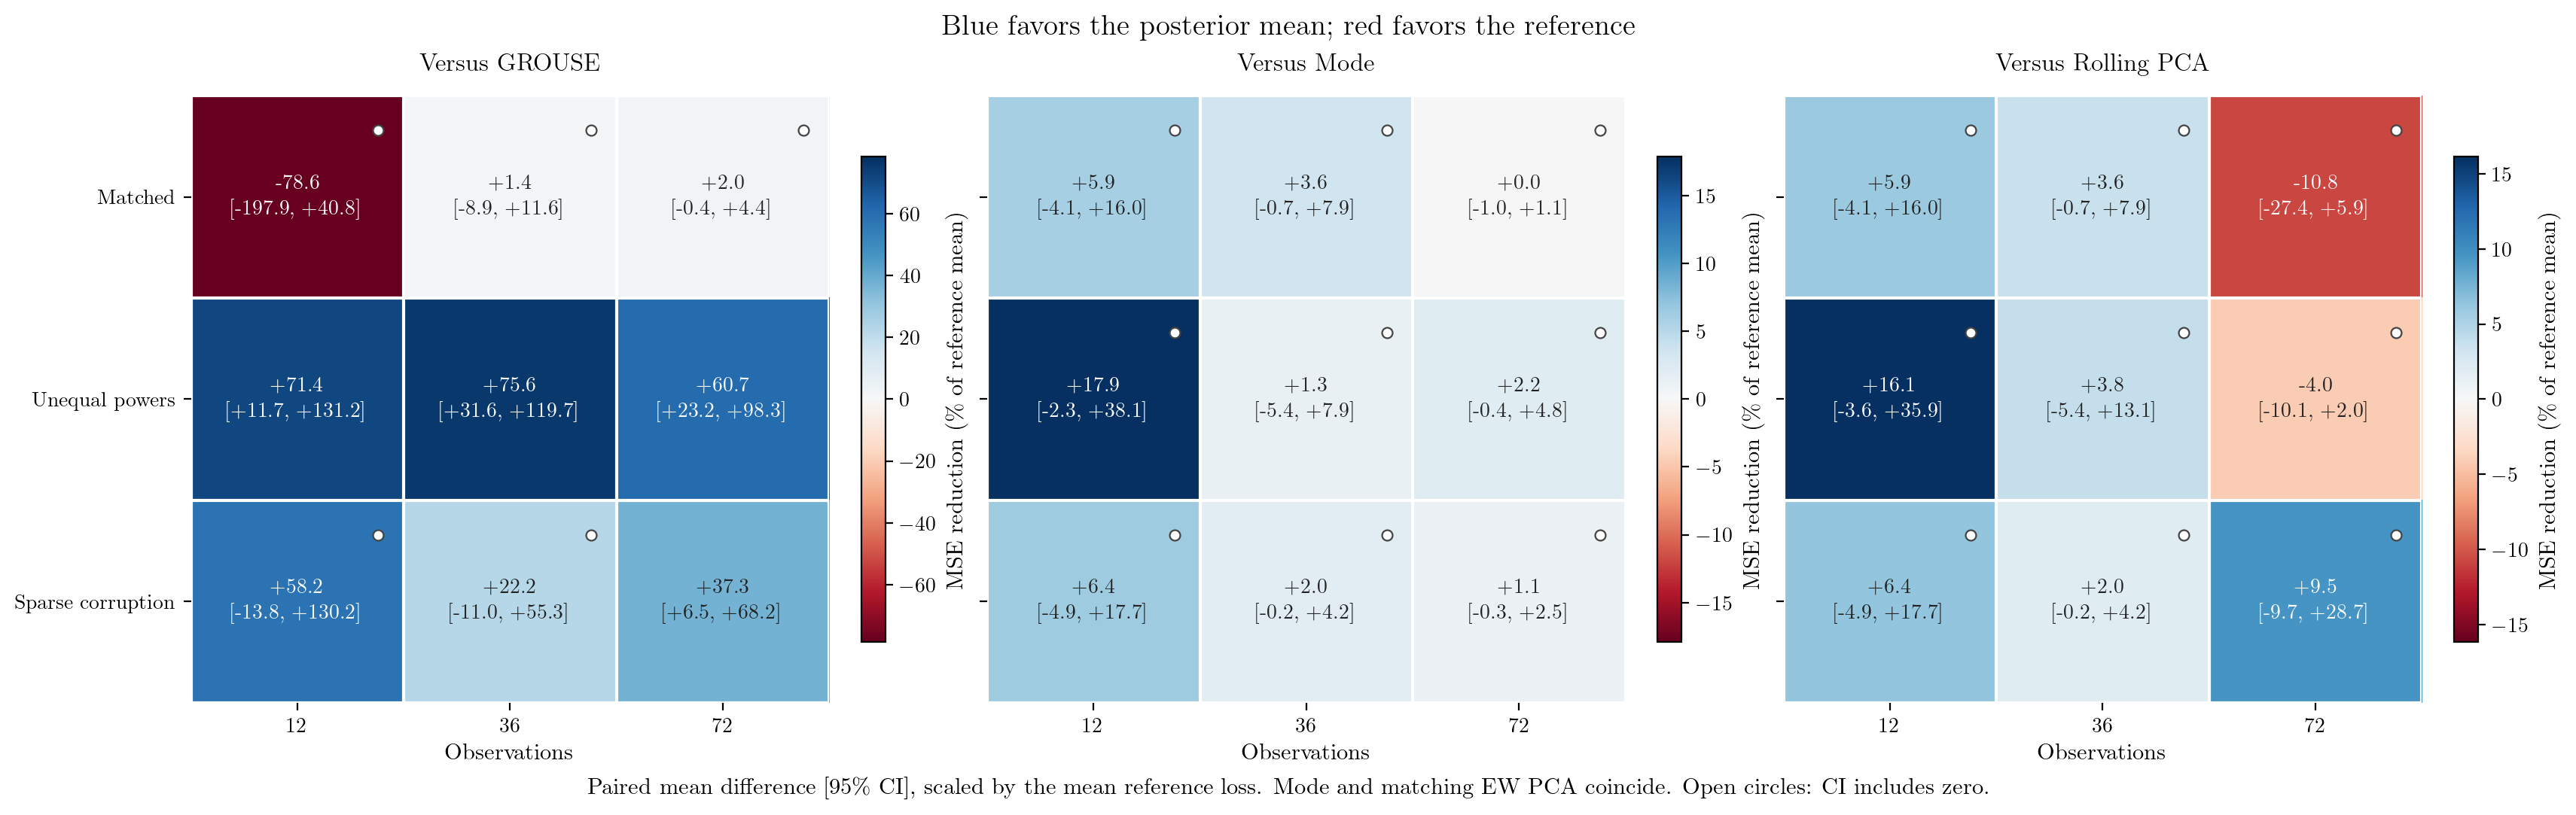

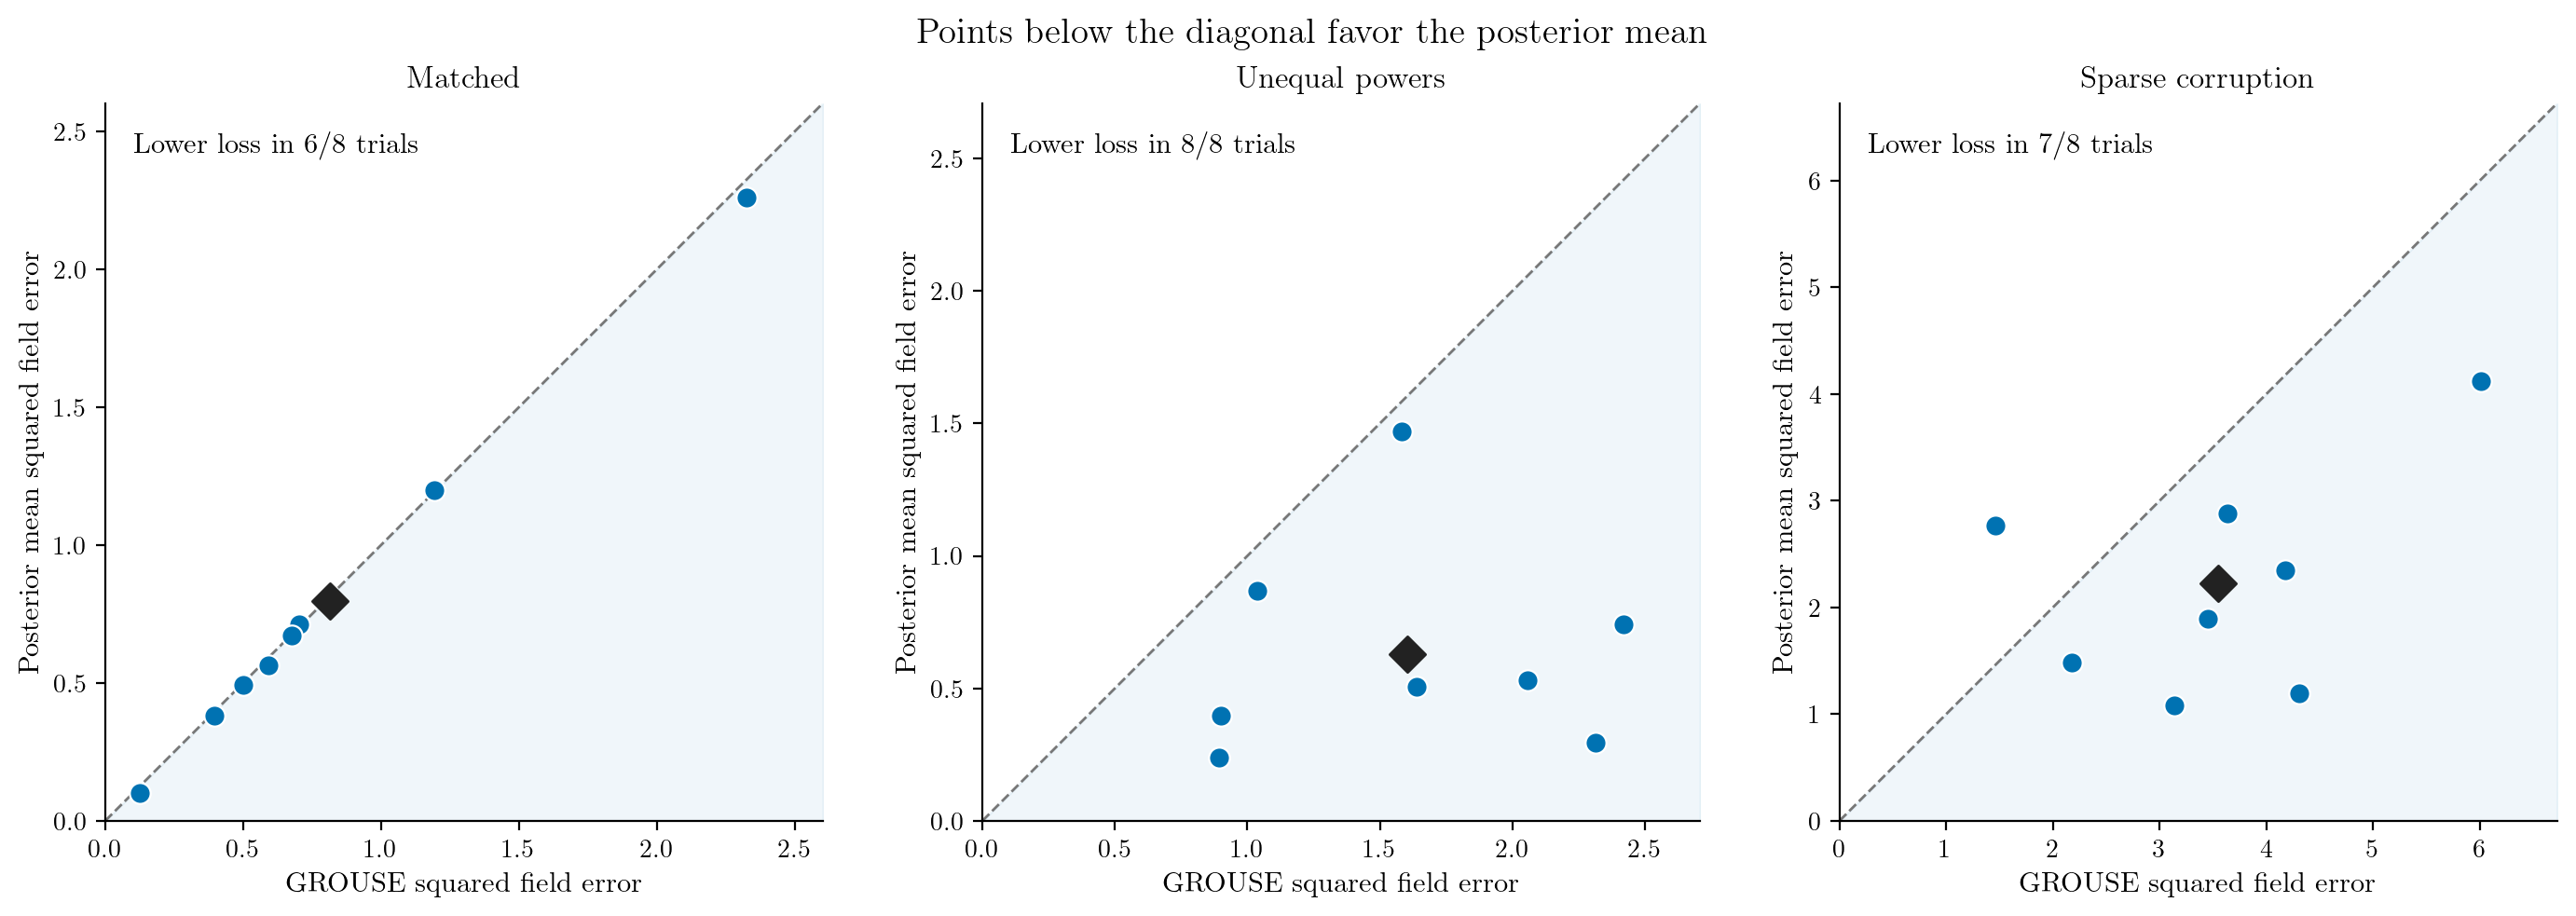

mean       std  count
scenario          method                                   
Matched           EW PCA          0.798064  0.674097      8
                  GROUSE          0.814070  0.681799      8
                  Mode            0.798064  0.674097      8
                  Oracle          0.657018  0.491007      8
                  Posterior mean  0.797867  0.668895      8
                  Rolling PCA     0.720331  0.541698      8
Sparse corruption EW PCA          2.245619  1.010239      8
                  GROUSE          3.544295  1.384297      8
                  Mode            2.245619  1.010239      8
                  Oracle          1.591154  0.858507      8
                  Posterior mean  2.220881  1.024672      8
                  Rolling PCA     2.454236  1.208633      8
Unequal powers    EW PCA          0.644547  0.394583      8
                  GROUSE          1.605028  0.621244      8
                  Mode            0.644547  0.394583      8
                  Oracle          0.549981  0.463607      8
                  Posterior mean  0.630485  0.399751      8
                  Rolling PCA     0.605958  0.381743      8

In [2]:
show(field_overview(result,path=OUT/'field_results'))
show(paired_field(result,path=OUT/'field_pairs'))
display(m[m.t==m.t.max()].groupby(['scenario','method']).field_squared_error.agg(['mean','std','count']))

## Inspect the spatial errors
The four field images share one amplitude scale. The two residual maps use a separate, common error scale, so spatial bias and smoothing are visible. This is one preassigned matched trajectory at the final observation, not a selected best reconstruction. Aggregate paired results above carry the comparison.

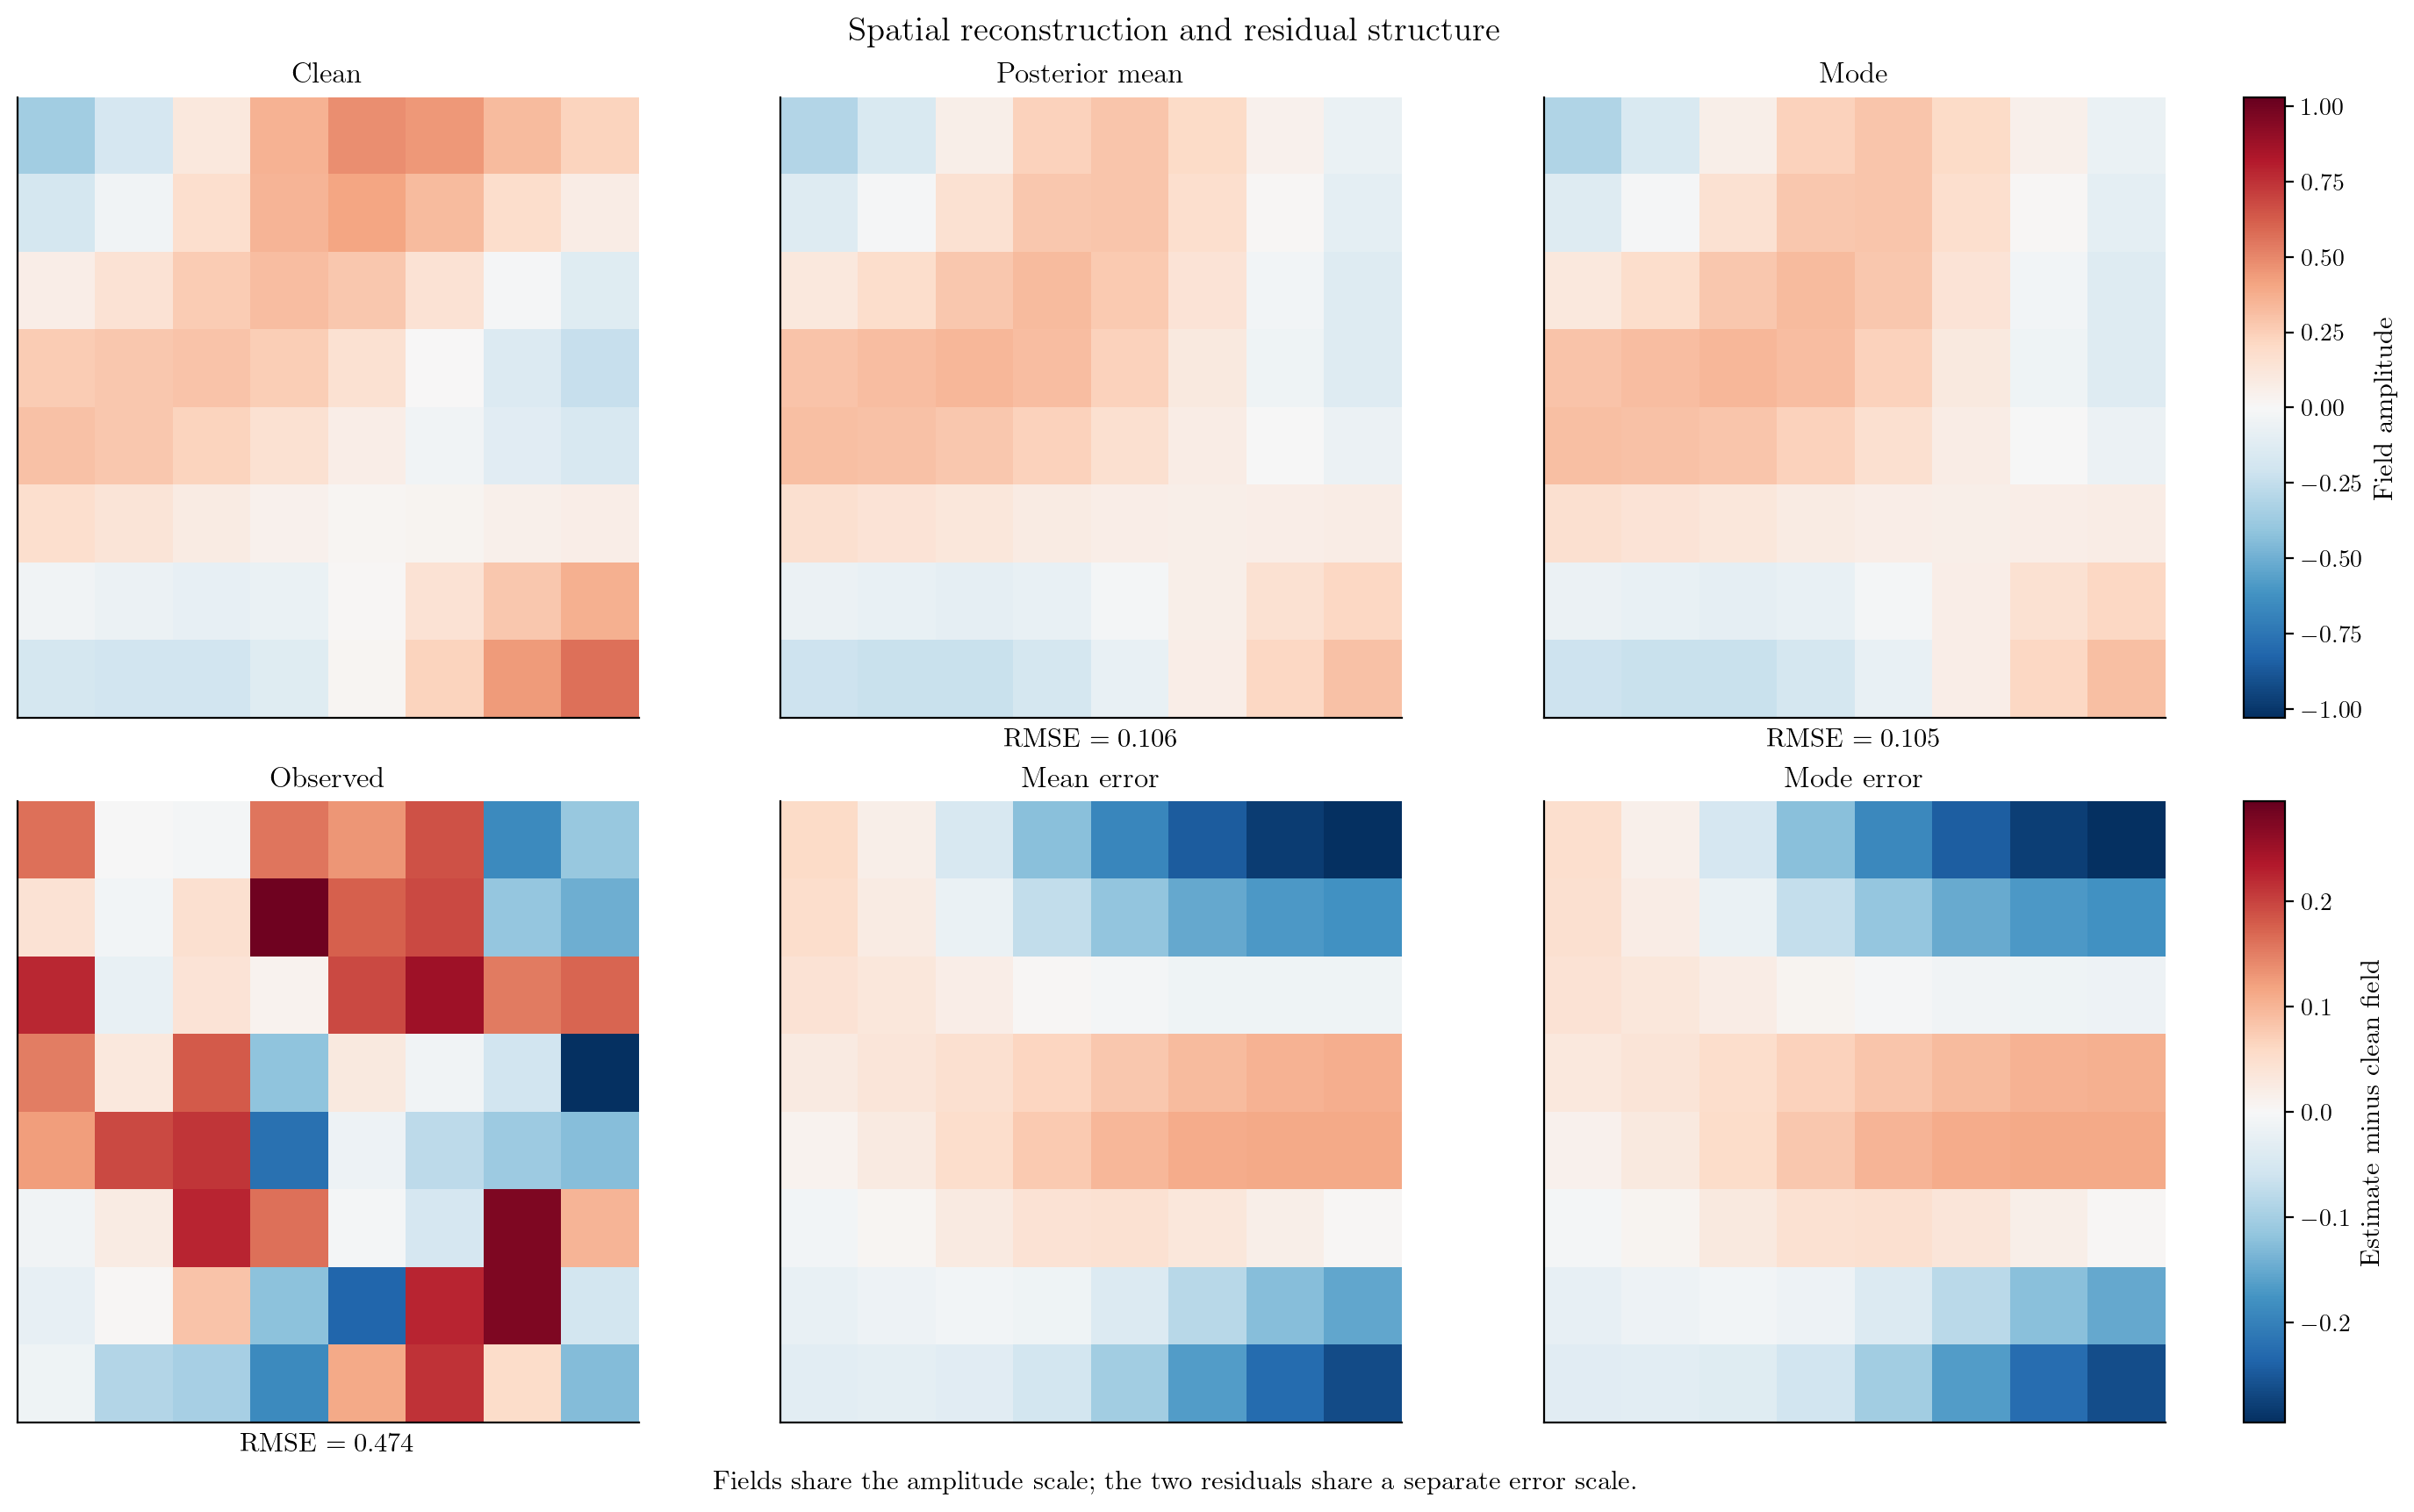

In [3]:
show(field_maps(result,path=OUT/'field_maps'))

## Known-input prediction is a different use of the posterior
Calibration inputs are preassigned independently of the hidden state and have transported ranks 6, 7, or 8. The left map measures realized response-error reduction against the mode. The right shows its nonnegative **posterior** excess risk from Eq. (30). The identity is conditional on a posterior; it does not require a realized true-state error ordering in every run.

These drifting paths do not test common-subspace global identifiability. The general theory notebook supplies the controlled ambiguity and excitation tests.

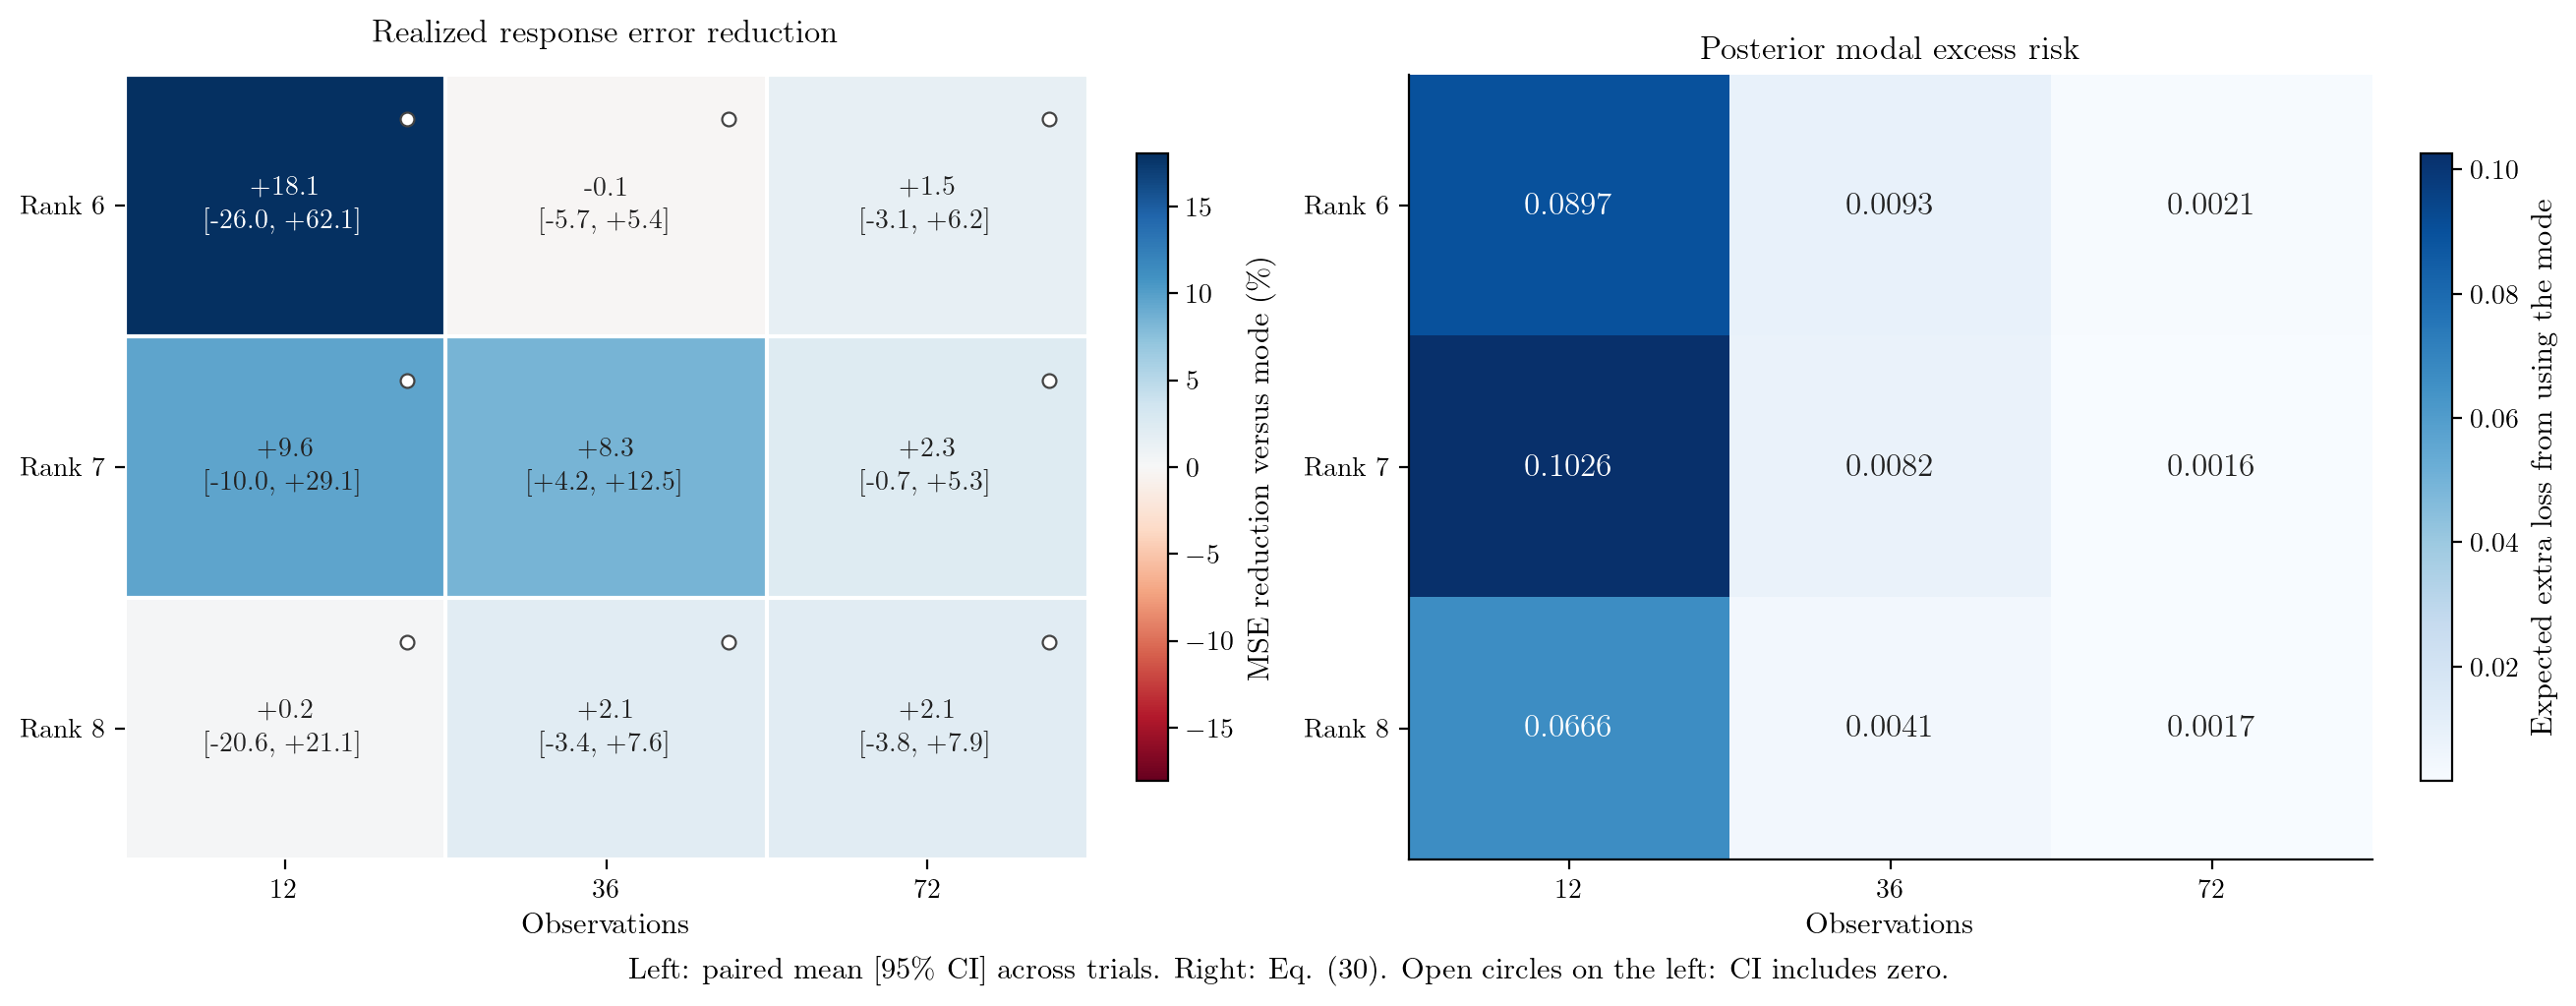

In [4]:
show(calibration_overview(result,path=OUT/'field_calibration'))

## Controlled prediction with identical information
A separate stationary real Gr(1,3) experiment tests the decision benefit under the actual Bayesian model. Every method receives the same passive training observations and fresh independent unit query vectors at decision time. No method is given hidden training inputs. Noise levels, rank, and prior-generating law are stated and shared.

The scalar-shrunk PCA control asks whether generic regularization is sufficient. GROUSE and shrinkage each receive the same number of independent validation candidates, separately per task and horizon. Posterior means use deterministic quadrature; all reported targets are checked against a higher order. All predeclared noise levels and horizons are shown, including ties or losses.

Decision study: loading verified cached tables


{'seed': 86021,
 'trials': 400,
 'validation_trials': 160,
 'checkpoints': [1, 2, 4, 8, 16],
 'noise_levels': [1.0, 0.2],
 'tau2': 1.0,
 'n': 3,
 'k': 1,
 'query_directions_per_trial': 8,
 'steps': [0.02, 0.05, 0.08, 0.2, 0.35, 0.5, 1.0, 2.0, 4.0],
 'rhos': [0.0, 0.1, 0.25, 0.4, 0.55, 0.7, 0.85, 0.95, 1.0],
 'loadings': [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 1000000.0],
 'candidate_count': 9,
 'coverage_trials_per_regime': 100,
 'coverage_mass': 0.95,
 'calibration_protocol': 'Exact joint Haar prior, stationary state and Gaussian likelihood; predeclared first coverage_trials trajectories at terminal time; not robustness under drift',
 'quadrature_order': 48,
 'reference_order': 96,
 'tolerance': 1e-08,
 'projection_protocol': 'Same passive observations; fresh independent unit queries supplied to every method at decision time',
 'reconstruction_protocol': 'Same current observation; known noise; Prior mean uses isotropic LMMSE, other methods use conditional Wiener shrinkage',
 'bea

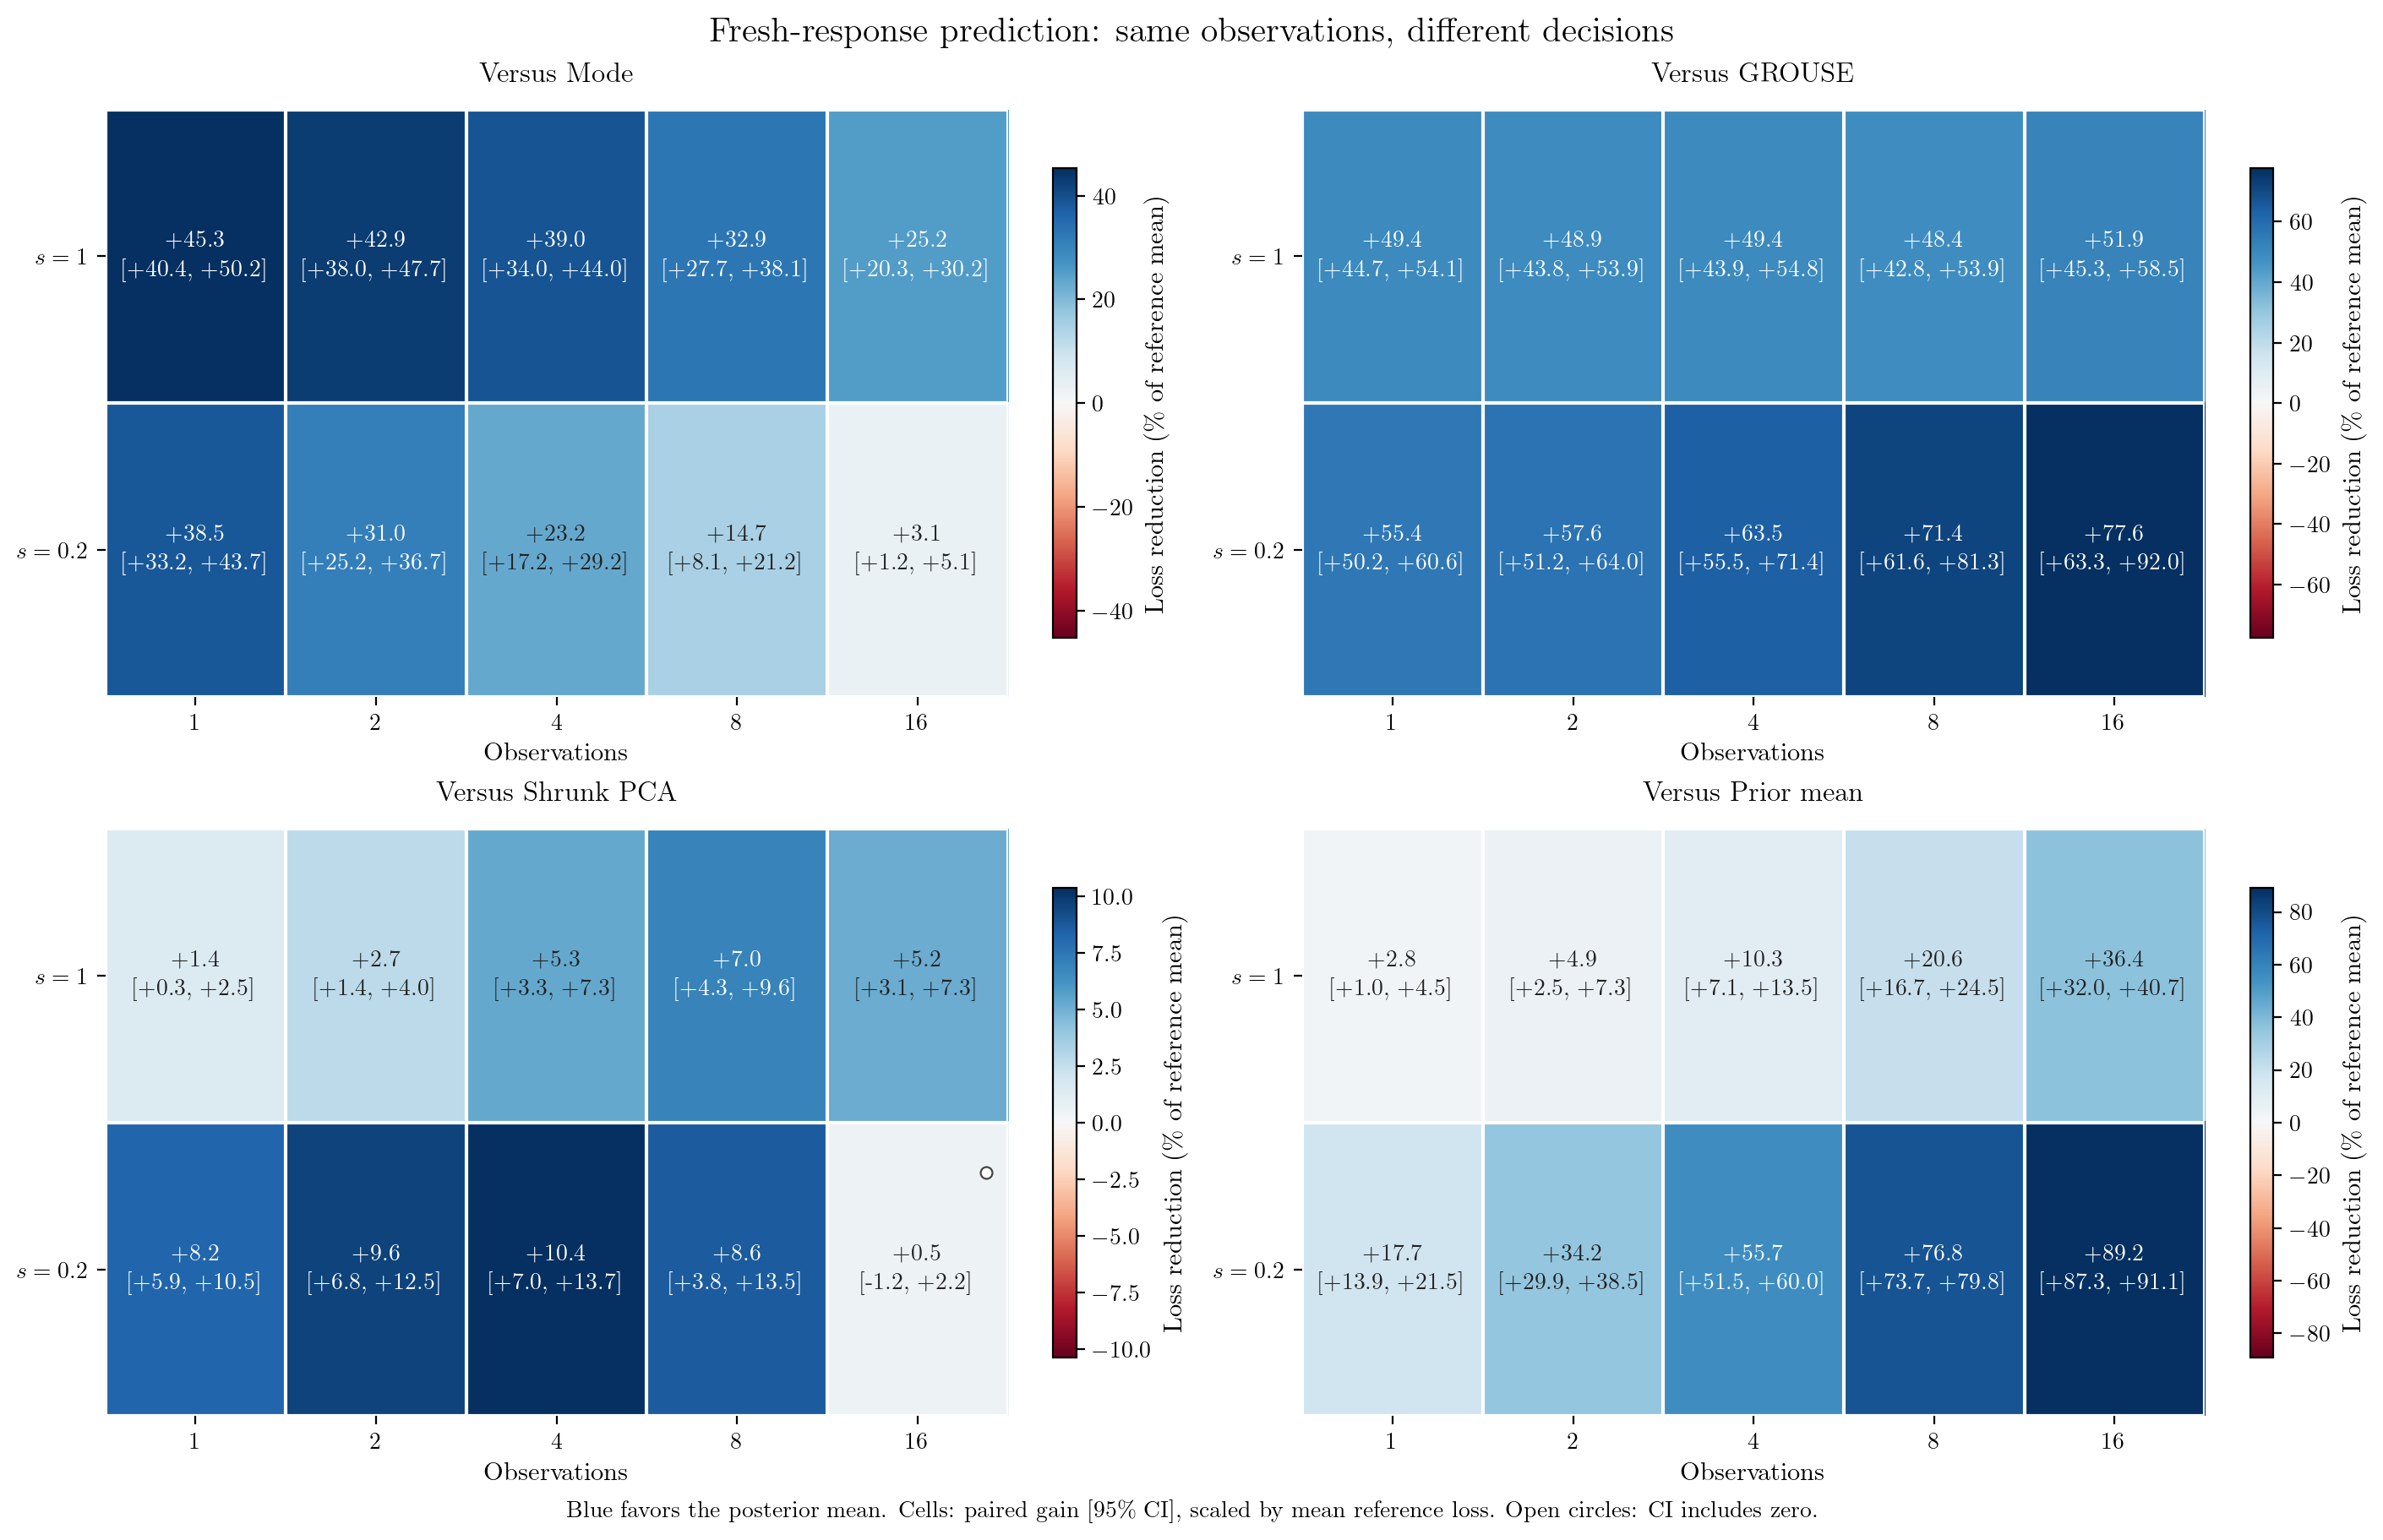

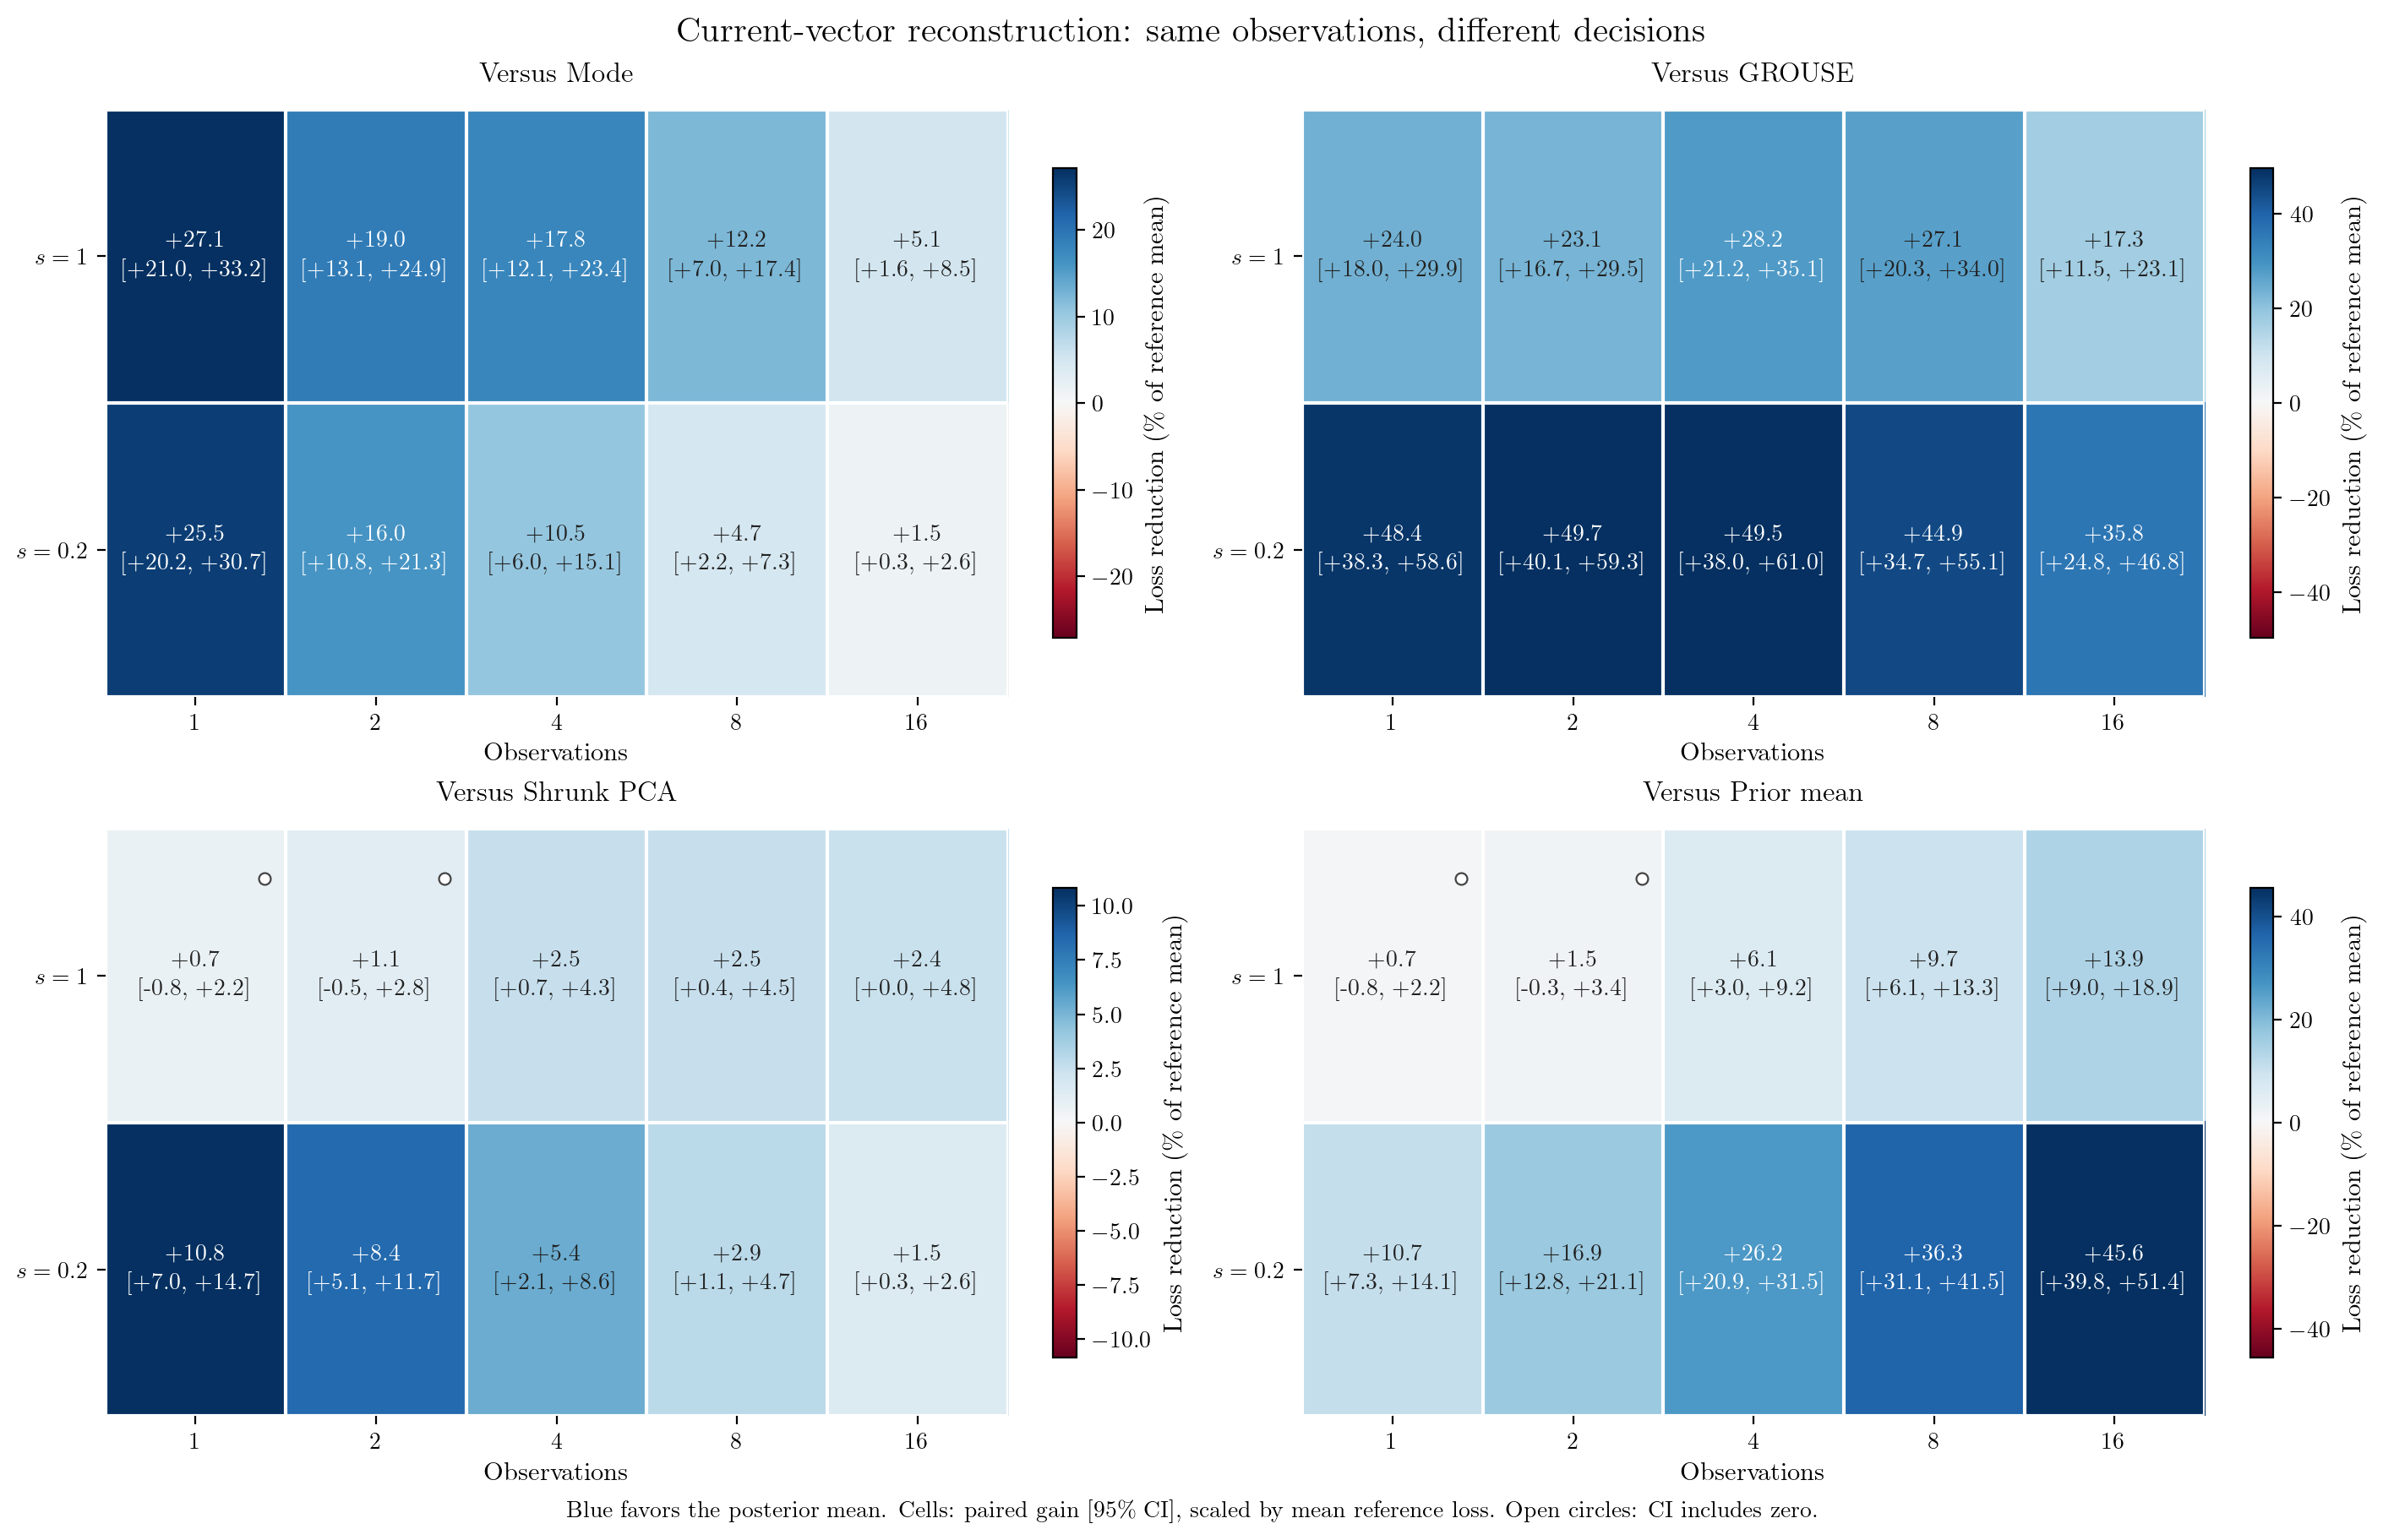

,regime,t,reference,baseline_loss,posterior_loss,reduction_percent,gain_low,gain_high
0,0,1,EW PCA,0.391274,0.213998,45.307486,0.158197,0.196355
1,0,1,GROUSE,0.422836,0.213998,49.389995,0.188809,0.228869
2,0,1,Mode,0.391274,0.213998,45.307486,0.158197,0.196355
3,0,1,Oracle,0.000000,0.213998,NaN,-0.219038,-0.208957
4,0,1,Prior mean,0.220091,0.213998,2.768558,0.002257,0.009930
5,0,1,Shrunk PCA,0.217046,0.213998,1.404608,0.000587,0.005510
38,0,4,EW PCA,0.323769,0.197477,39.006788,0.110003,0.142581
39,0,4,GROUSE,0.389908,0.197477,49.352985,0.171218,0.213645
40,0,4,Mode,0.323769,0.197477,39.006788,0.110003,0.142581
41,0,4,Oracle,0.000000,0.197477,NaN,-0.204881,-0.190072


In [5]:
# This runs only if the controlled-study source or parameters changed.
subprocess.run([sys.executable,str(ROOT/'scripts/run_decision_study.py')],cwd=ROOT,check=True)
study=load_study(ROOT)
display(study['config'])
assert study['accuracy'].reference_difference.max()<=study['config']['tolerance']

show(gain_maps(study,task='Projection',path=OUT/'field_low_data_prediction'))
show(gain_maps(study,task='Reconstruction',path=OUT/'field_low_data_reconstruction'))
display(study['paired'][(study['paired'].task=='Projection')&study['paired'].t.isin([1,4,16])][['regime','t','reference','baseline_loss','posterior_loss','reduction_percent','gain_low','gain_high']])

## Calibrated under the model does not mean robust to drift
The controlled experiment's coverage panel uses the first predeclared trajectories at the terminal time and continuous-CDF region thresholds. Its risk panel bins independent terminal trajectories by predicted risk and compares them with observed loss.

The application coverage below is a different evaluation law: it contains unmodelled motion and approximate forgetting. In the original matched-covariance field run, both nominal 95% regions have 0/8 terminal coverage. This contrast identifies the state-model limitation; it is not a claim that point trackers intrinsically provide competing credible regions.

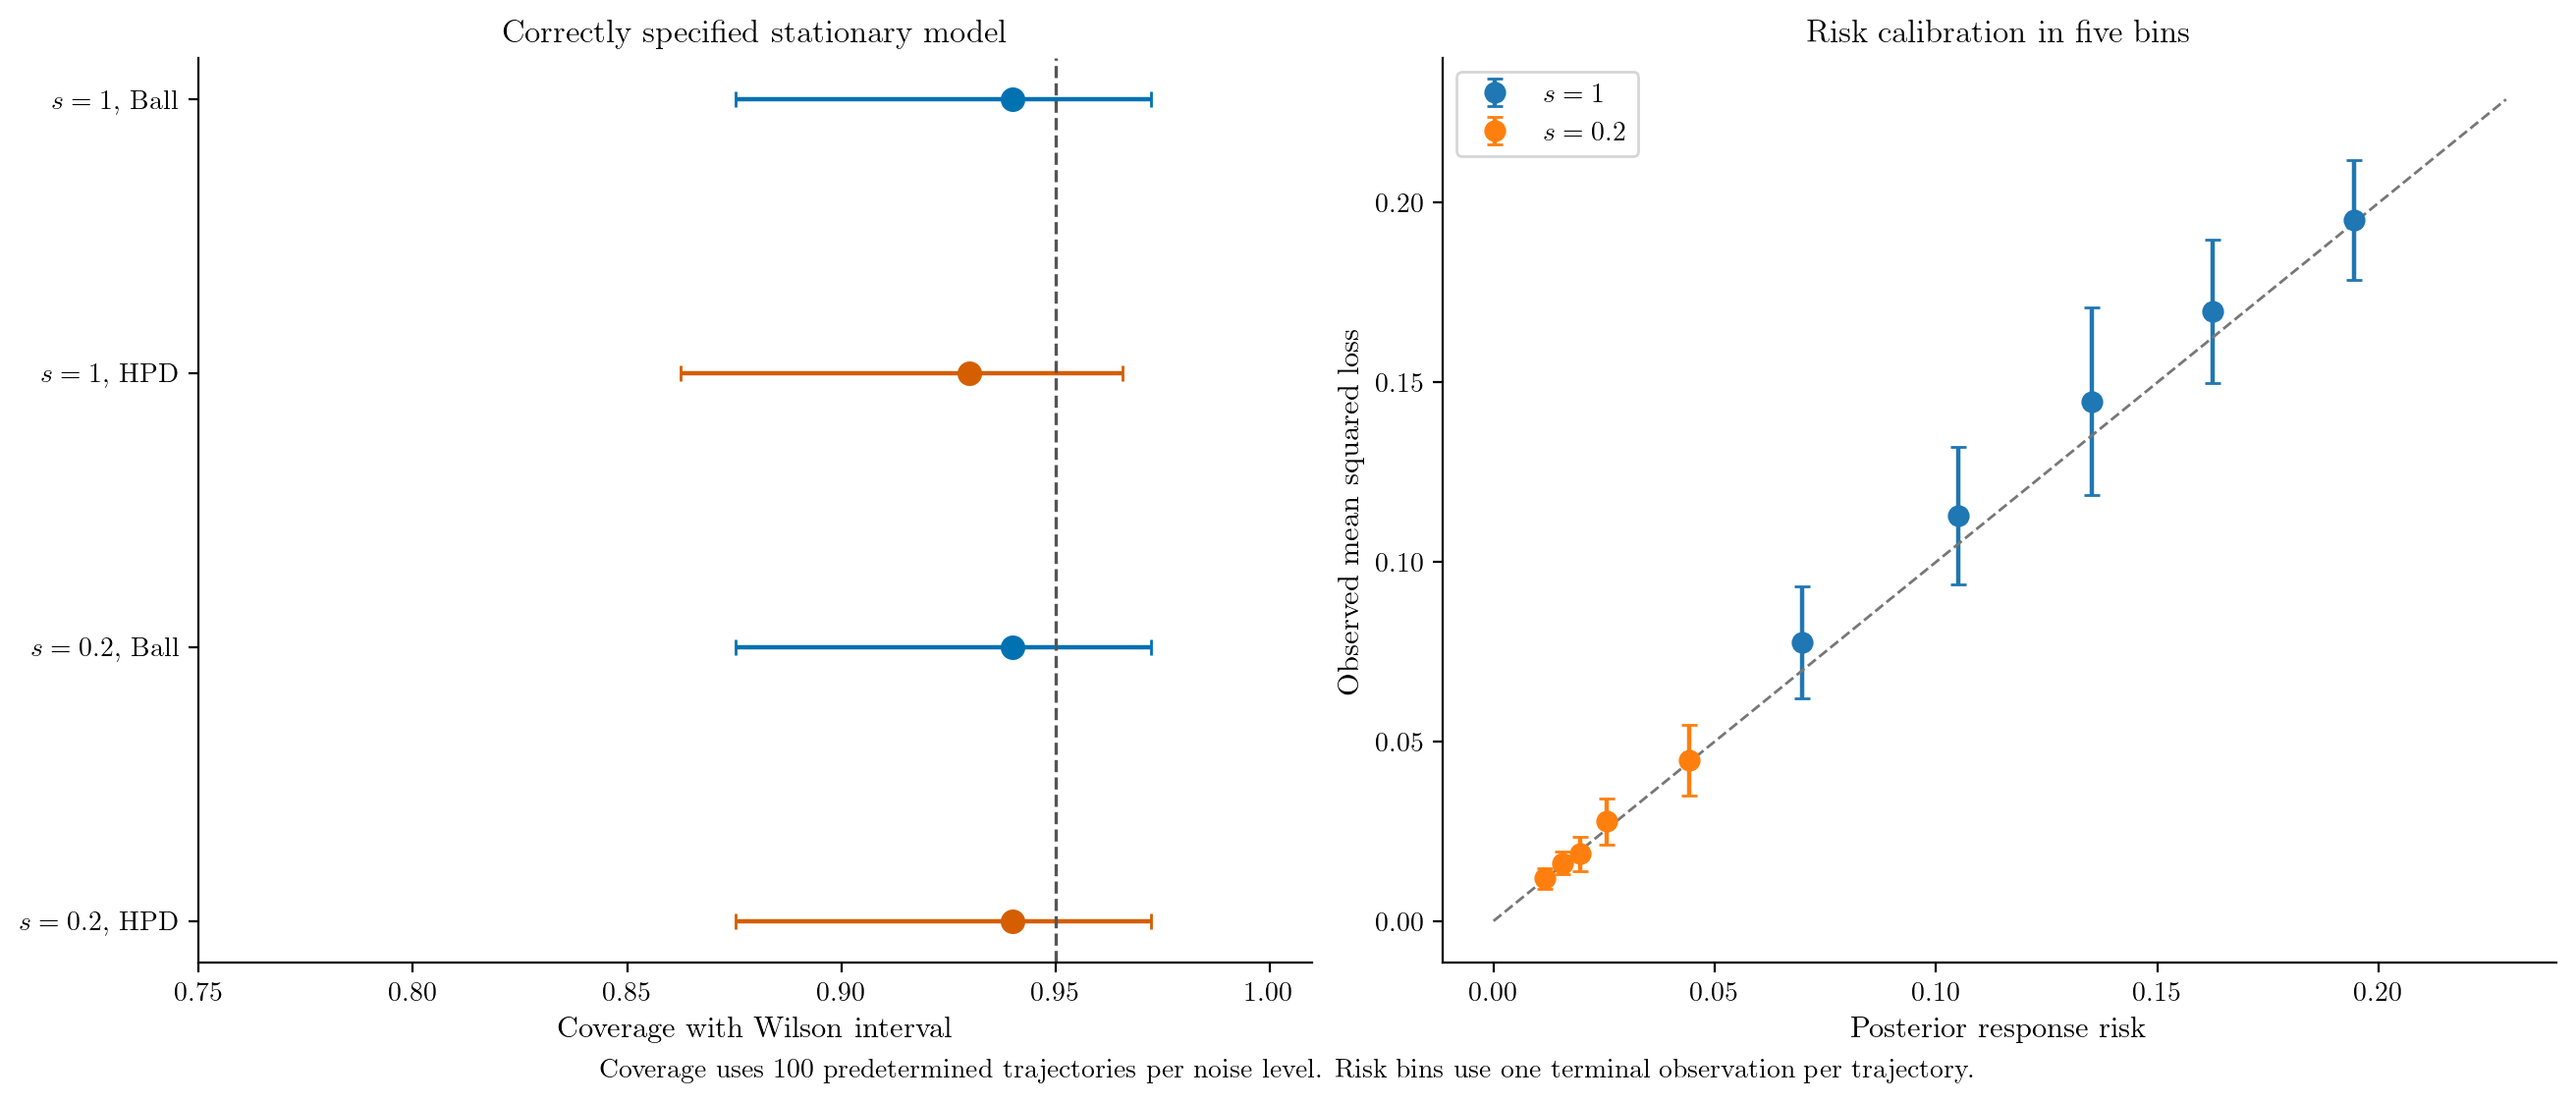

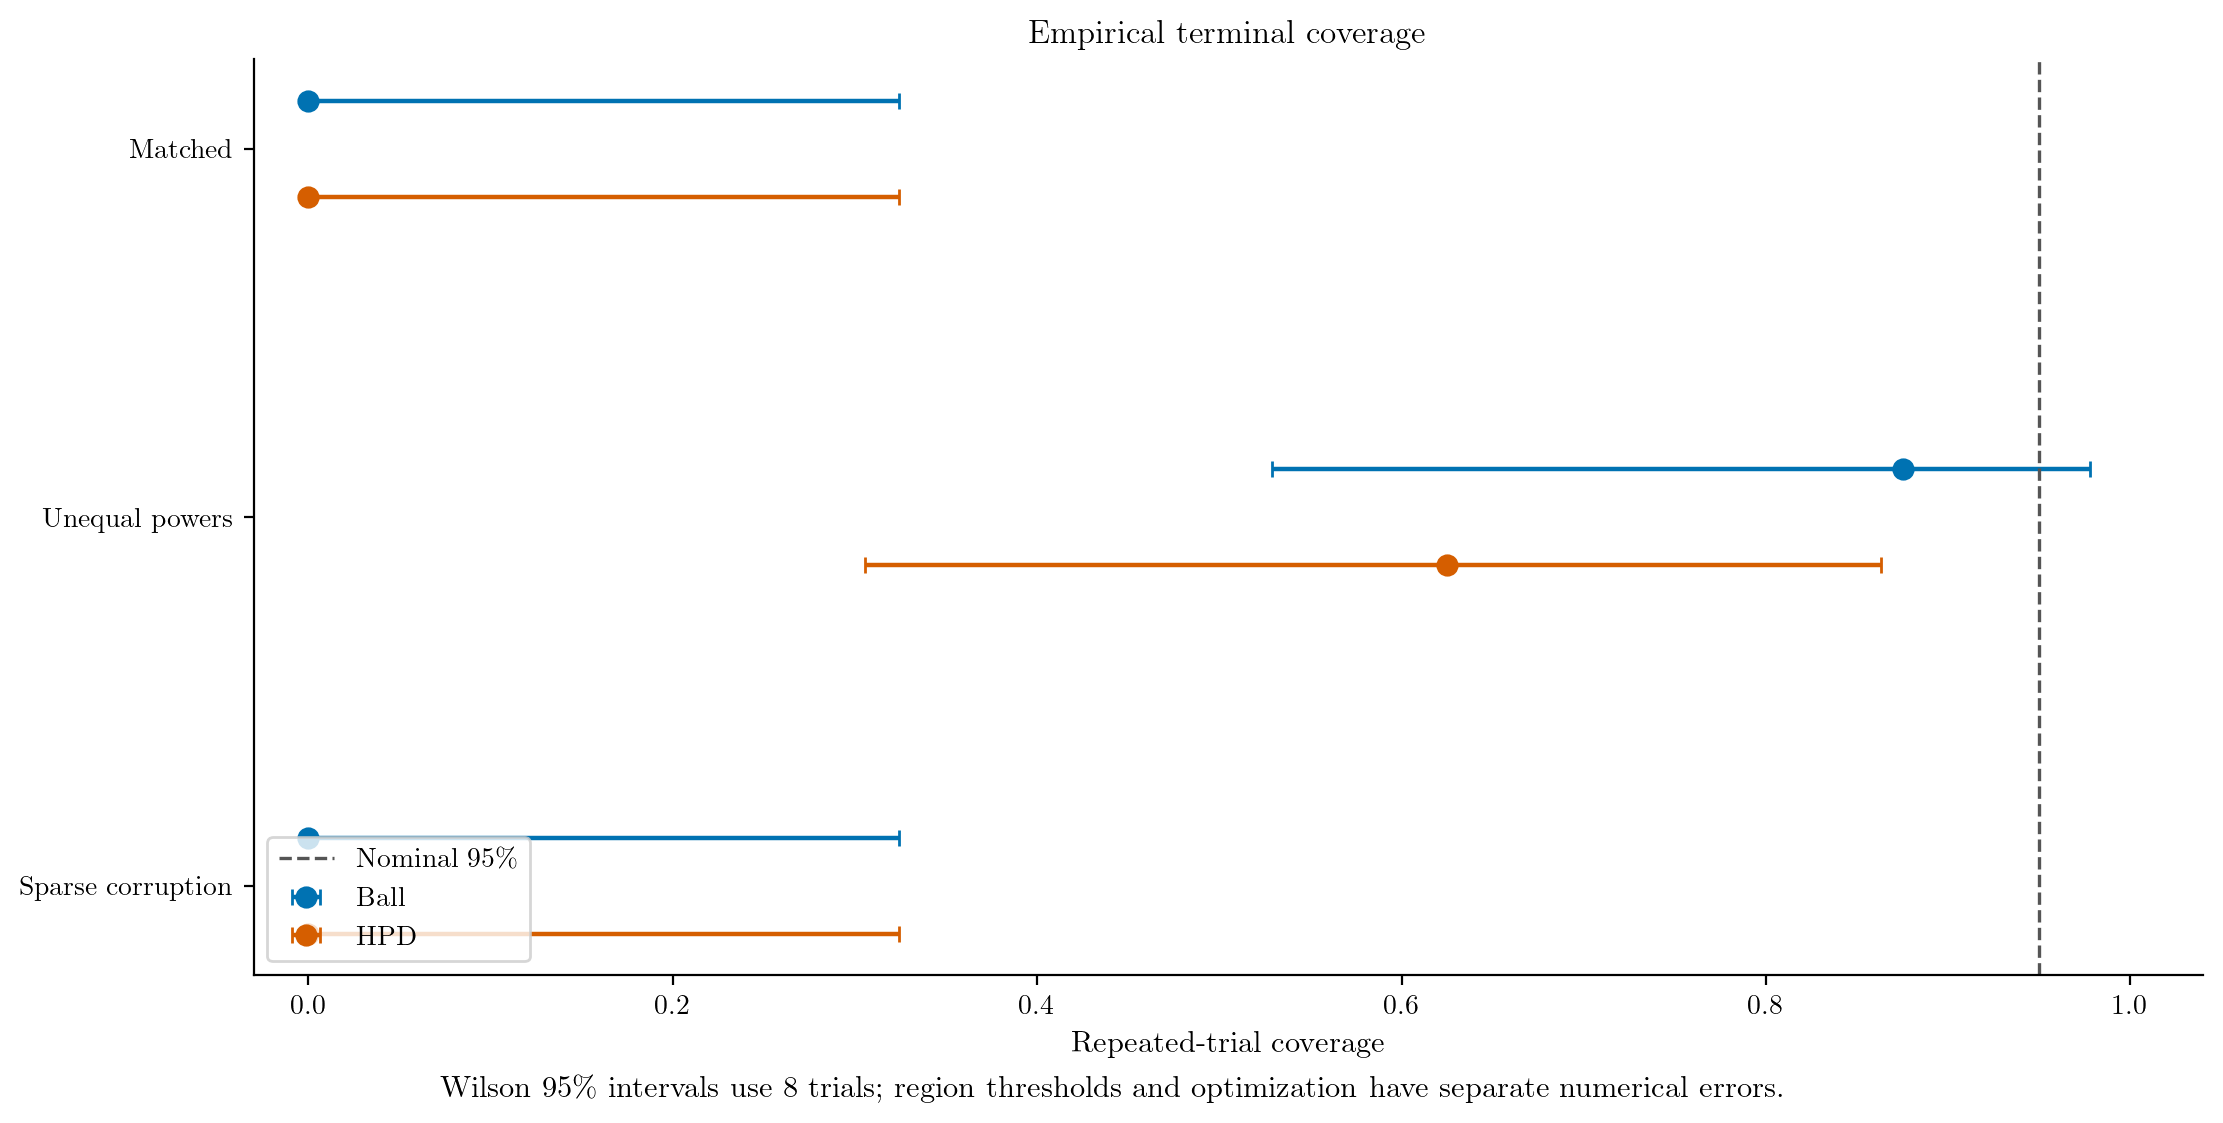

In [6]:
show(decision_calibration(study,path=OUT/'field_model_calibration'))
show(coverage_regions(result,path=OUT/'field_regions'))

## Noise estimation needs the uncertainty term
Separate fits use eight stored priors and two EM iterations. The stacked bars decompose the same window residual statistic into the residual of the mean response and the nonnegative subspace-uncertainty term. Treating the mean residual alone as the variance statistic omits that term.

Sampled high-dimensional EM ascent remains unverified. Predictive scores are recorded before fitting and assimilation, with Gaussian constants retained. Different cells correspond to different incoming observations; an increasing log score is not evidence of ascent of one fixed objective. Importance ESS and sampler ESS answer different questions.

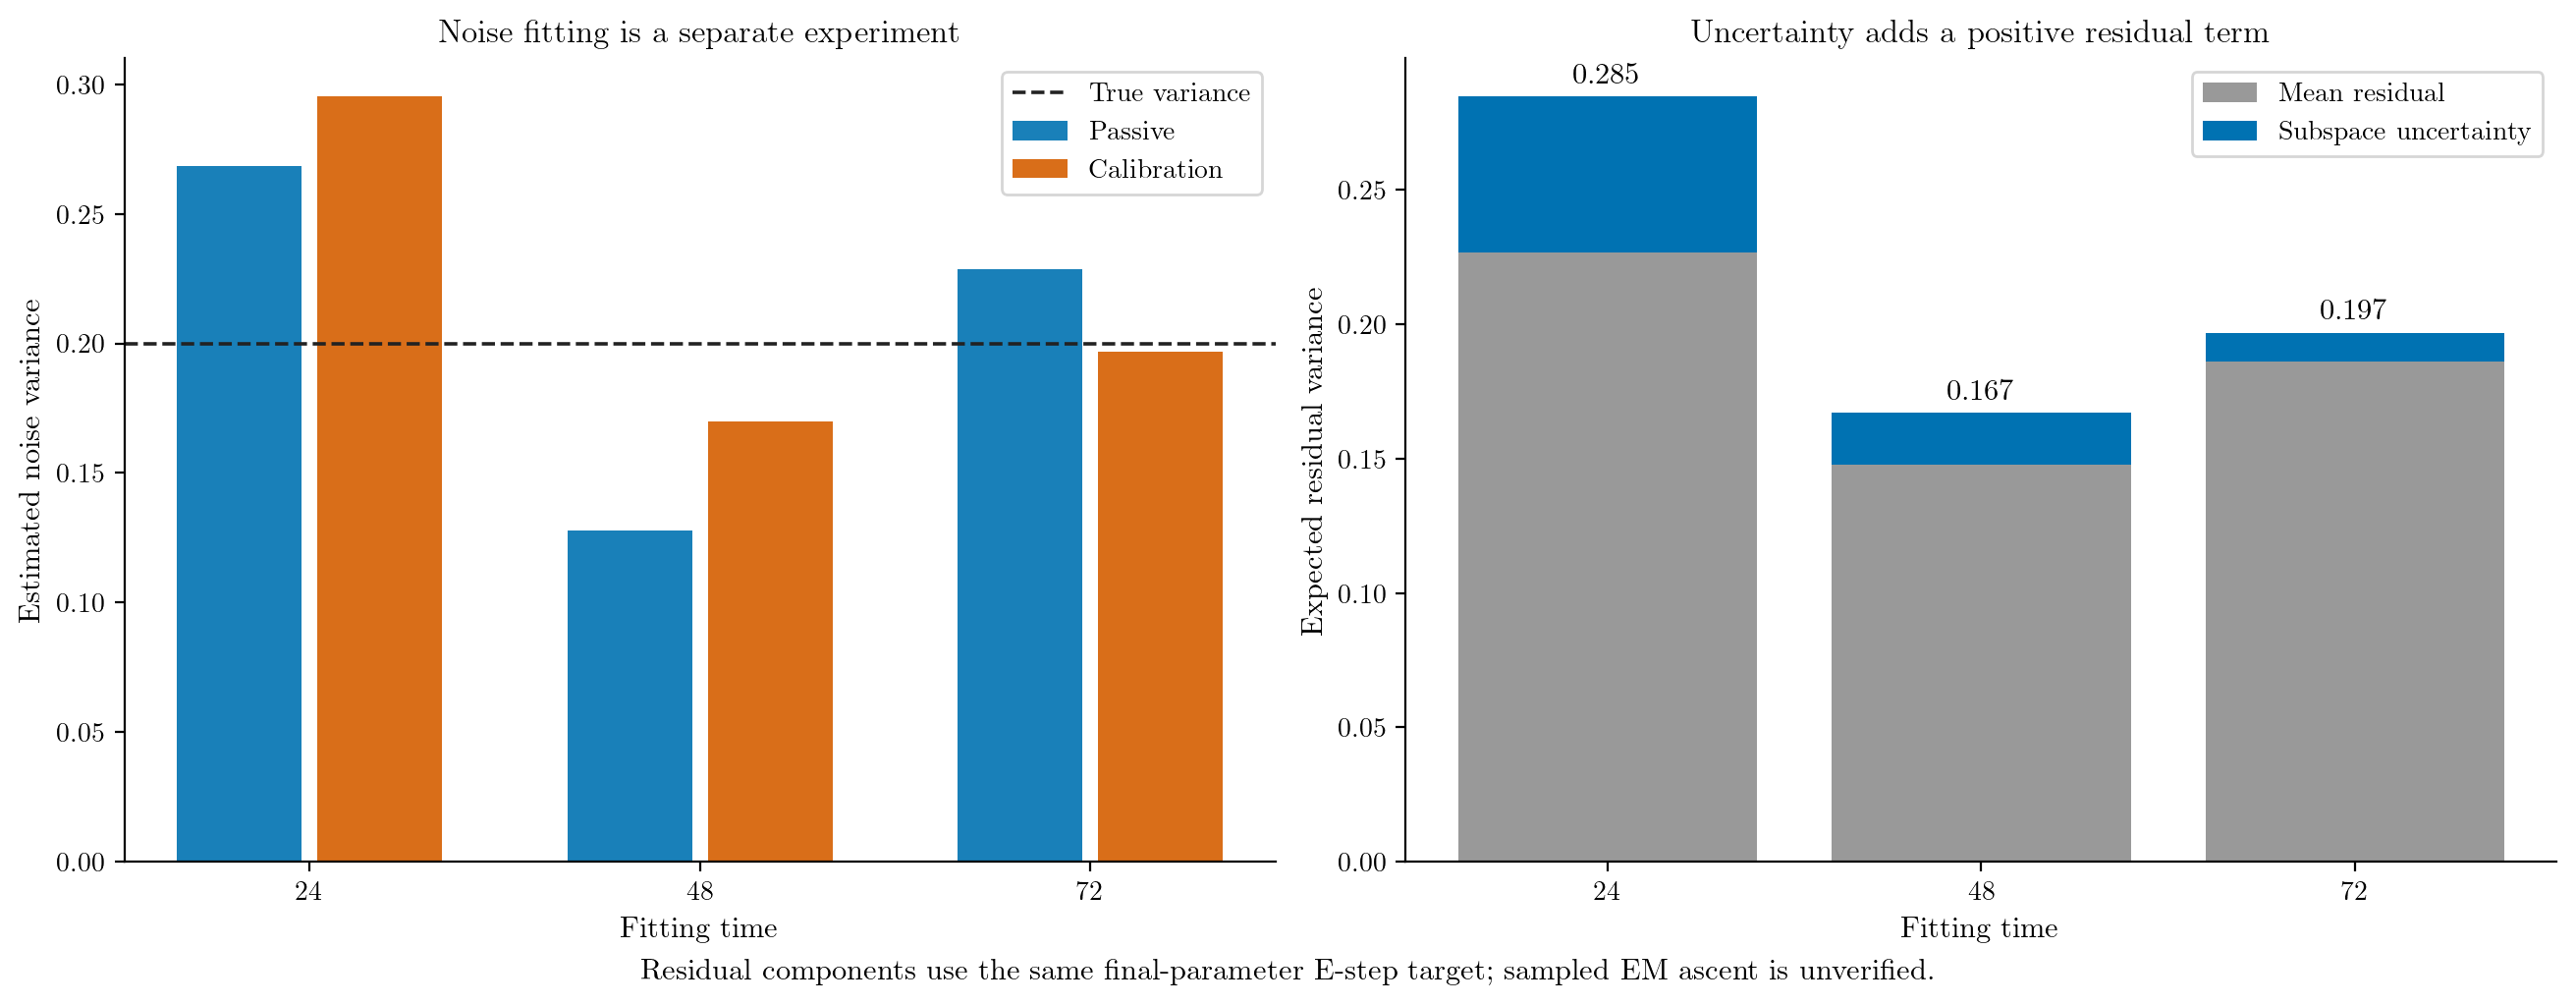

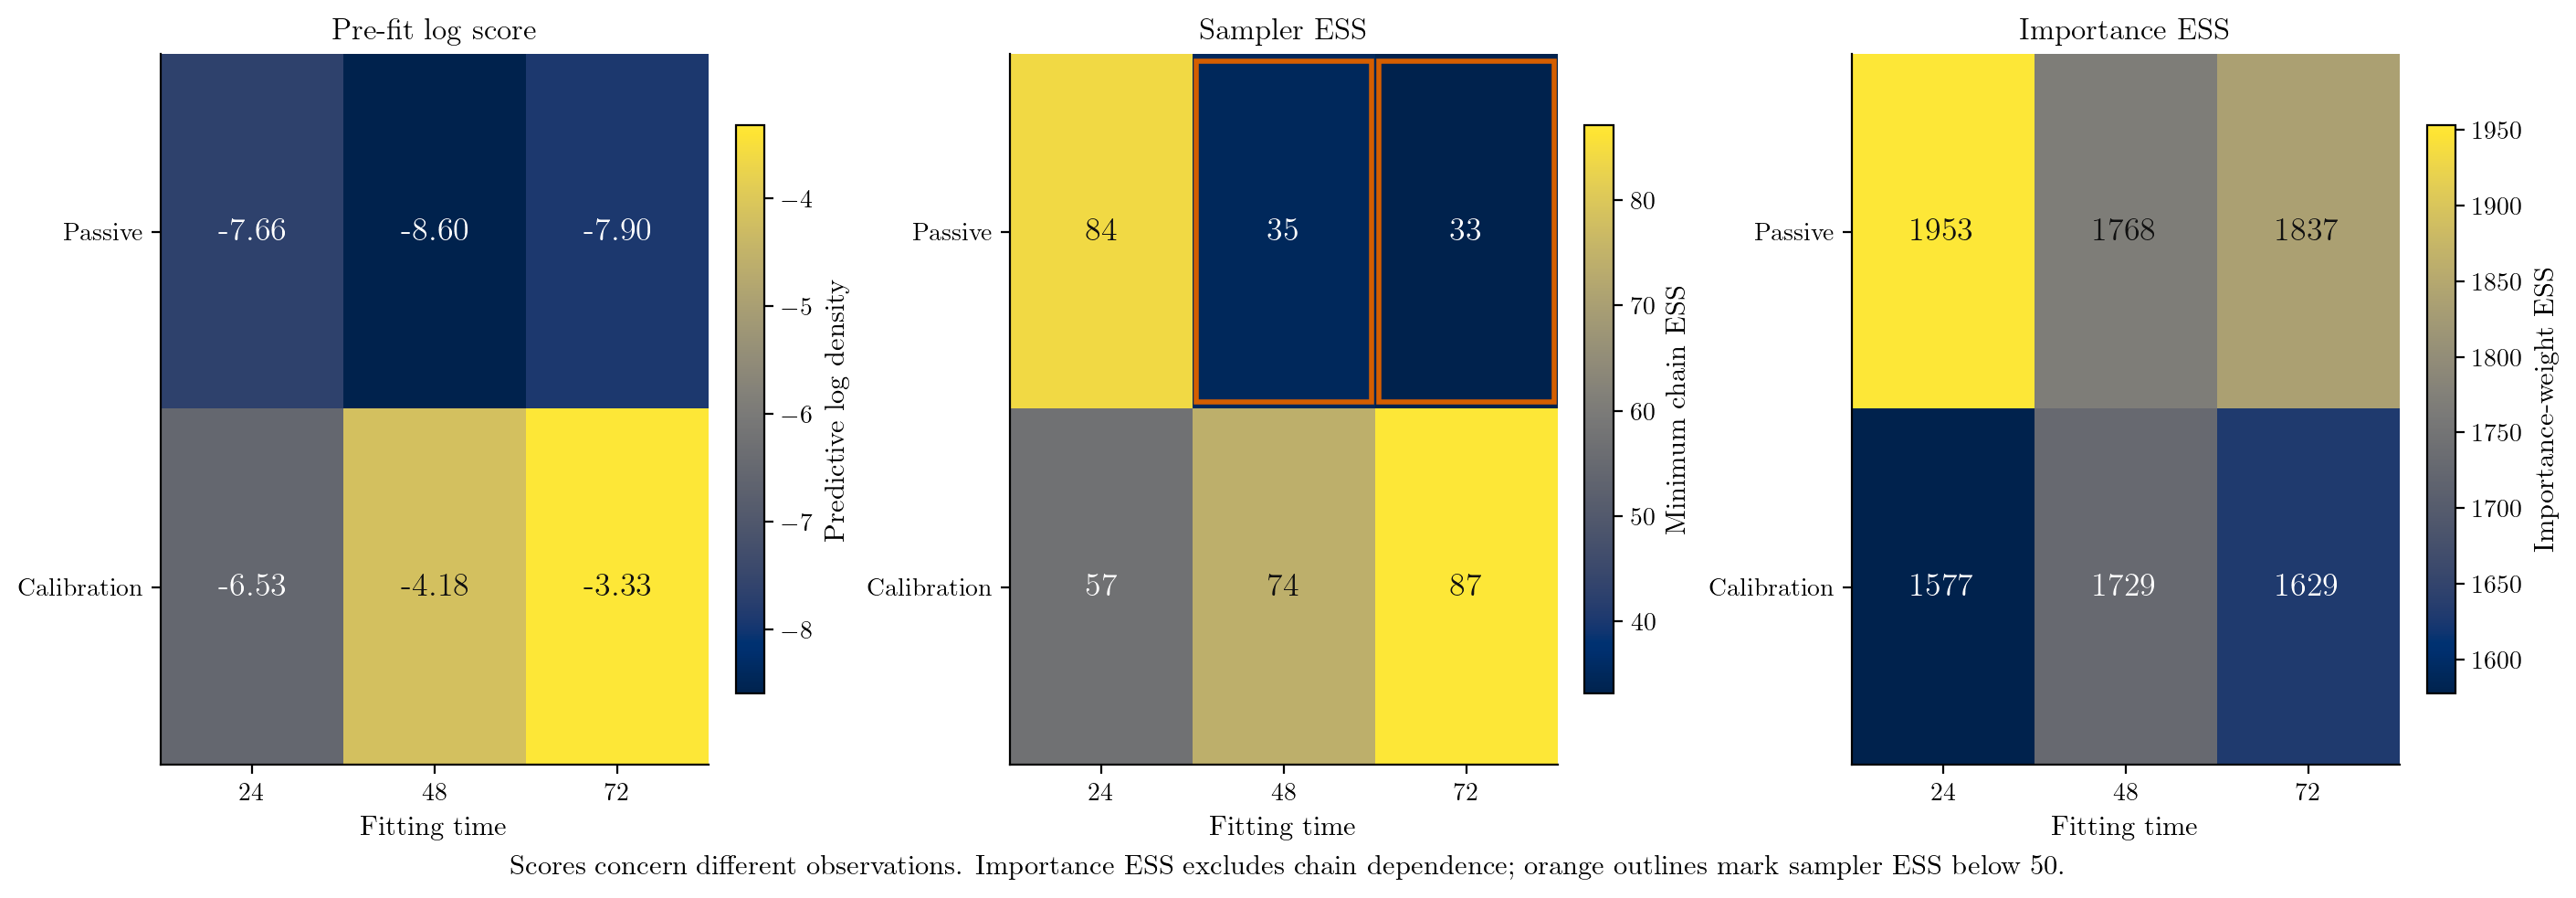

,protocol,t,score_chain_difference,minimum_ess,numerical_ascent_verified
0,Passive,24,0.012346,36.578213,False
1,Passive,48,0.012969,23.719823,False
2,Passive,72,0.019493,21.995372,False
3,Calibration,24,0.038457,22.086918,False
4,Calibration,48,0.071518,26.758641,False
5,Calibration,72,0.027570,27.430202,False


In [7]:
show(noise_overview(result,path=OUT/'field_noise'))
show(predictive_scores(result,path=OUT/'field_scores'))
cal=noise[noise.protocol=='Calibration']
assert np.allclose(cal.expected_residual_variance,cal.naive_residual_variance+cal.uncertainty_variance)
display(noise[['protocol','t','score_chain_difference','minimum_ess','numerical_ascent_verified']])

## Decide whether the extra computation is worthwhile
The original implementation spends far more time sampling moments than updating a point estimate. The horizontal axis counts cumulative tracking and moment work through 72 measurements, excluding the final field matrix-vector multiplication. Oracle timing is omitted. The mode also represents the matching EW-PCA control; its duplicate point is not plotted.

If the requirement is only a cheap subspace basis or matched passive reconstruction, these results do not justify the full sampling overhead. Posterior computation is motivated by uncertainty-aware response decisions, directional risk and bounds, or noise diagnostics. It can be requested only when those quantities are needed; faster accurate moment backends remain an implementation opportunity.

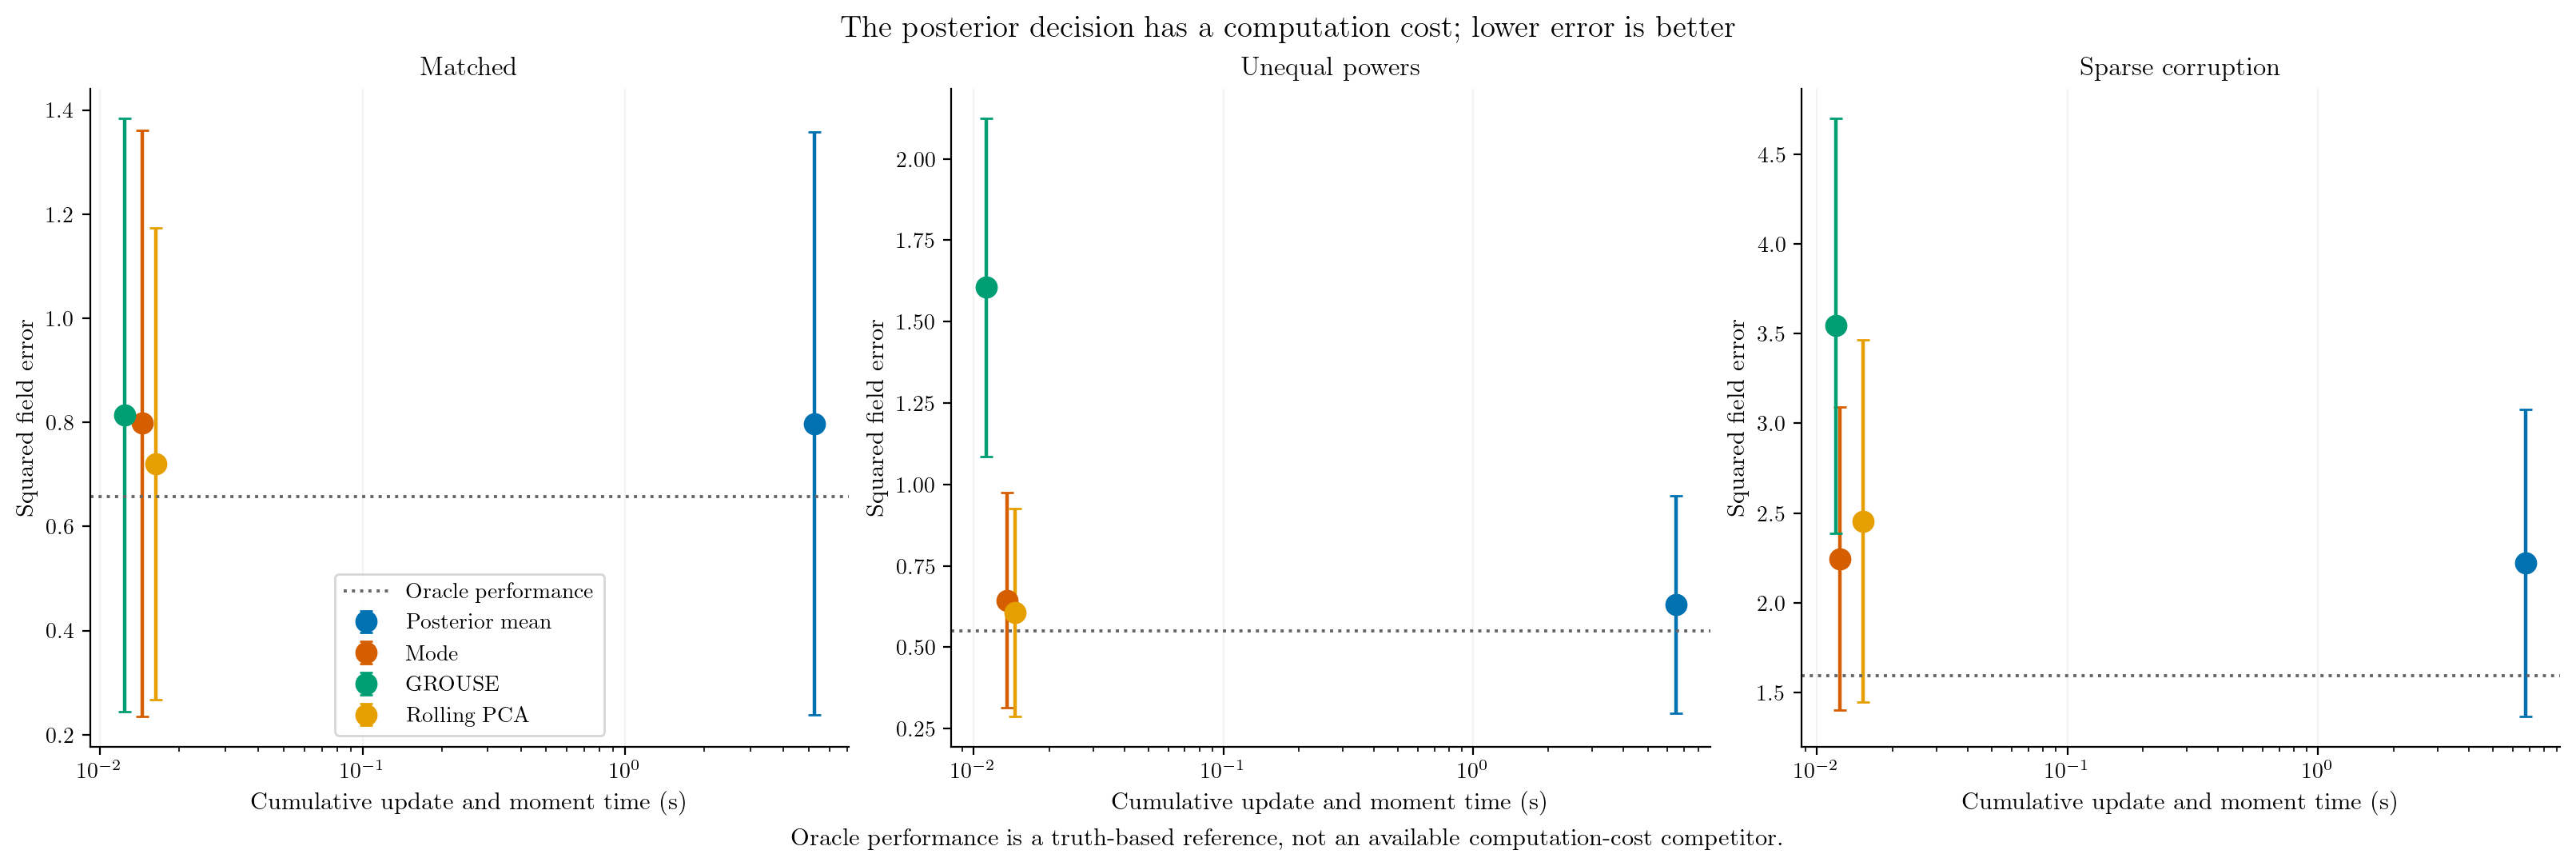

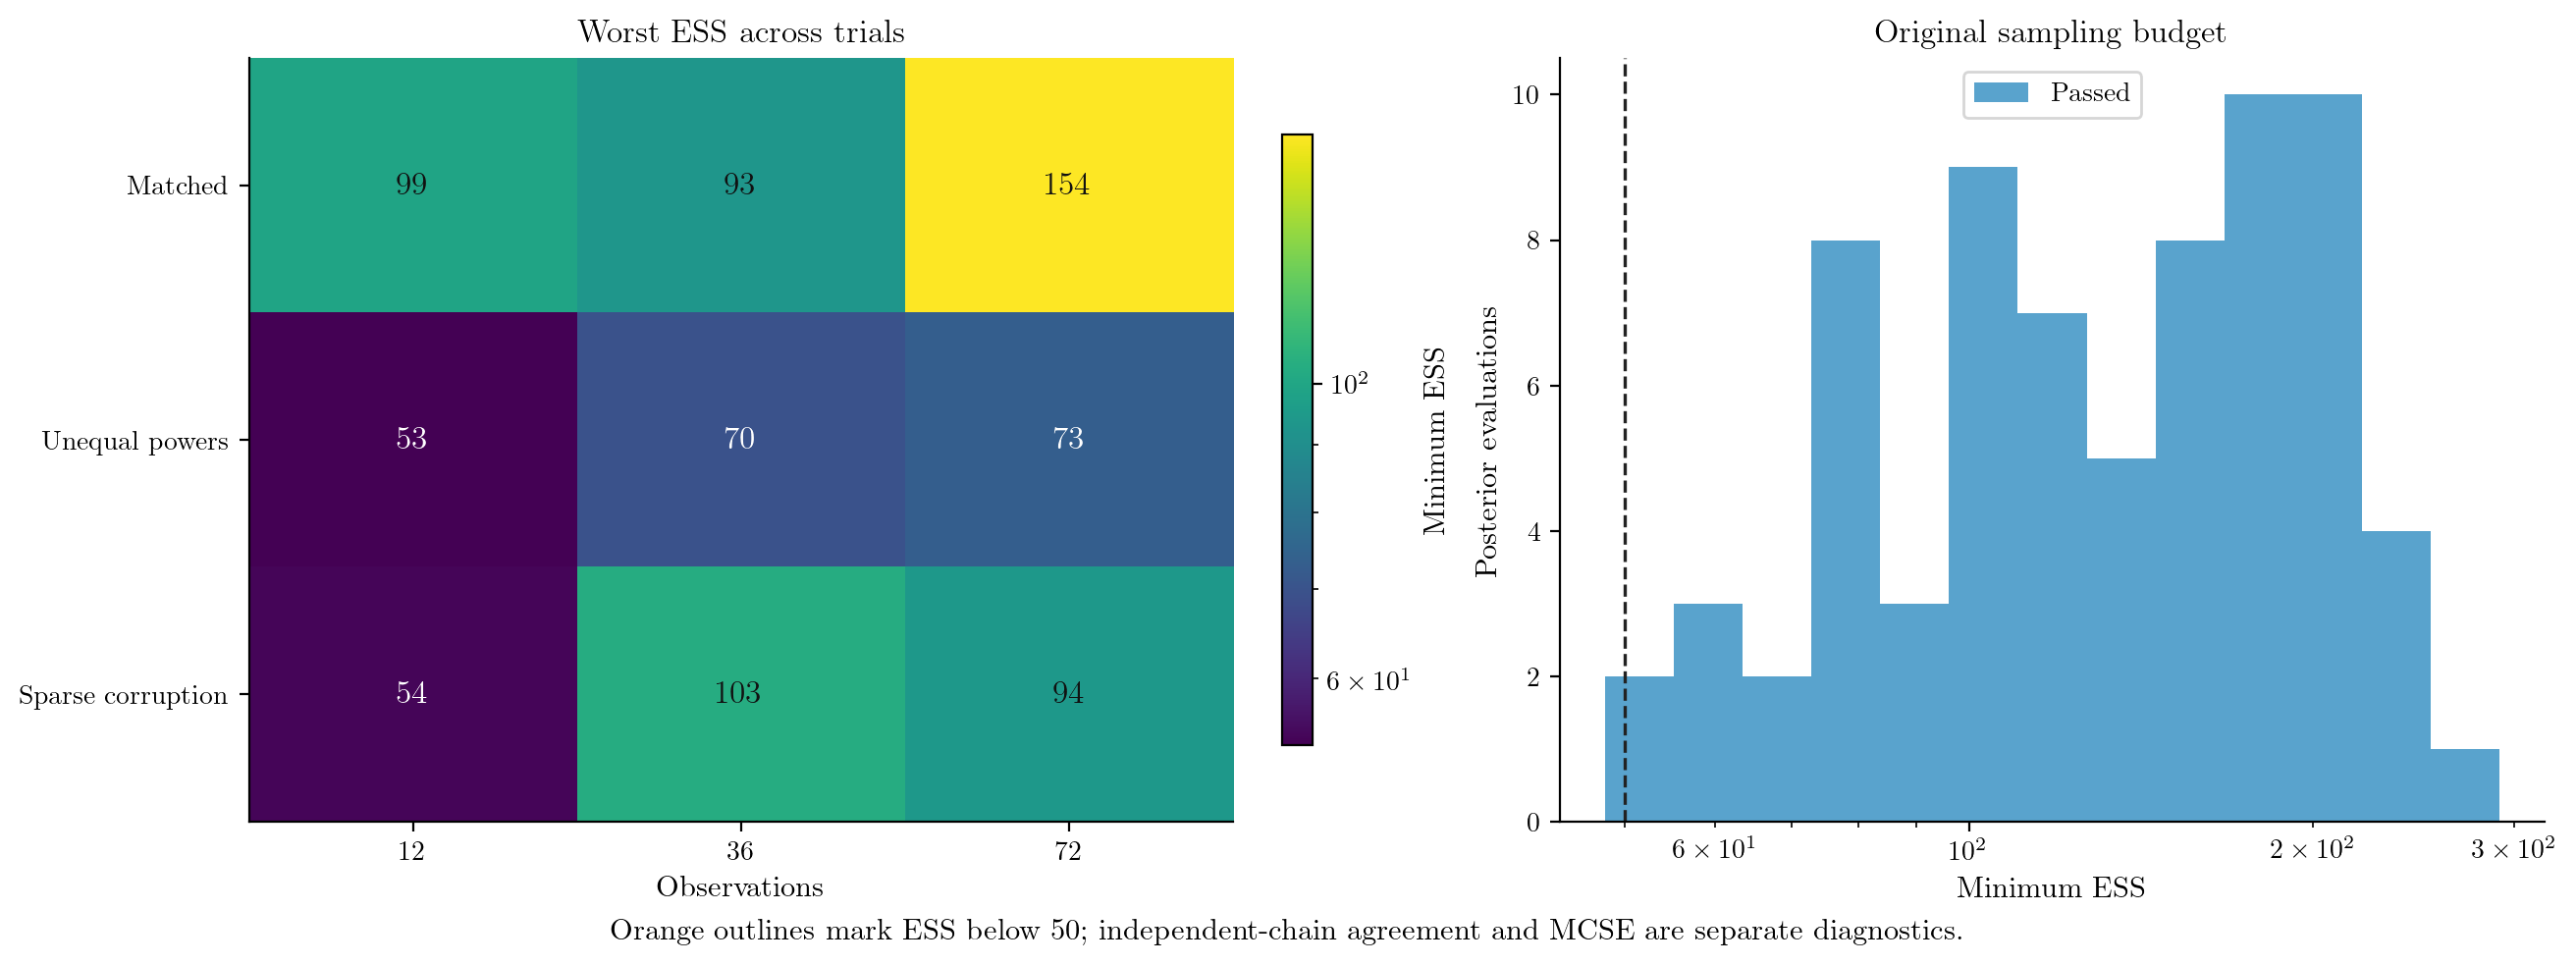

,decision_seconds,update_seconds
method,,
EW PCA,0.007874,0.007874
GROUSE,0.011537,0.011537
Mode,0.012546,0.012546
Oracle,0.000000,0.000000
Posterior mean,5.302137,0.012546
Rolling PCA,0.015285,0.015285


In [8]:
show(cost_tradeoff(result,field=True,path=OUT/'field_tradeoff'))
show(sampler_overview(result,path=OUT/'field_accuracy'))
p=m[m.method=='Posterior mean']
assert p.sampling_ok.astype(bool).all() and c.sampling_ok.astype(bool).all()
display(m[m.t==m.t.max()].groupby('method')[['decision_seconds','update_seconds']].median())